# Delhi Air Quality (AQI) Forecasting — Time Series Project
**Milestone 1:** EDA  |  **Milestone 2:** preprocessing + classical models  |  **Milestone 3:** advanced models, tuning, comparison and insights

Run the notebook from top to bottom with `city_day.csv` in the working folder.

## Milestone 1: Exploratory Data Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("city_day.csv")

df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:
delhi = df[df["City"] == "Delhi"].copy()

delhi["Date"] = pd.to_datetime(delhi["Date"])

delhi = delhi.sort_values("Date")

print("Number of records:", len(delhi))
print("Start date:", delhi["Date"].min())
print("End date:", delhi["Date"].max())

Number of records: 2009
Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00


In [ ]:
print(delhi.info())
print(delhi.columns)

<class 'pandas.DataFrame'>
RangeIndex: 2009 entries, 10229 to 12237
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        2009 non-null   str           
 1   Date        2009 non-null   datetime64[us]
 2   PM2.5       2007 non-null   float64       
 3   PM10        1932 non-null   float64       
 4   NO          2007 non-null   float64       
 5   NO2         2007 non-null   float64       
 6   NOx         2009 non-null   float64       
 7   NH3         2000 non-null   float64       
 8   CO          2009 non-null   float64       
 9   SO2         1899 non-null   float64       
 10  O3          1925 non-null   float64       
 11  Benzene     2009 non-null   float64       
 12  Toluene     2009 non-null   float64       
 13  Xylene      1228 non-null   float64       
 14  AQI         1999 non-null   float64       
 15  AQI_Bucket  1999 non-null   str           
dtypes: datetime64[us](1), float64(

In [ ]:
missing = delhi.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

Xylene        781
SO2           110
O3             84
PM10           77
AQI_Bucket     10
AQI            10
NH3             9
PM2.5           2
NO              2
NO2             2
dtype: int64


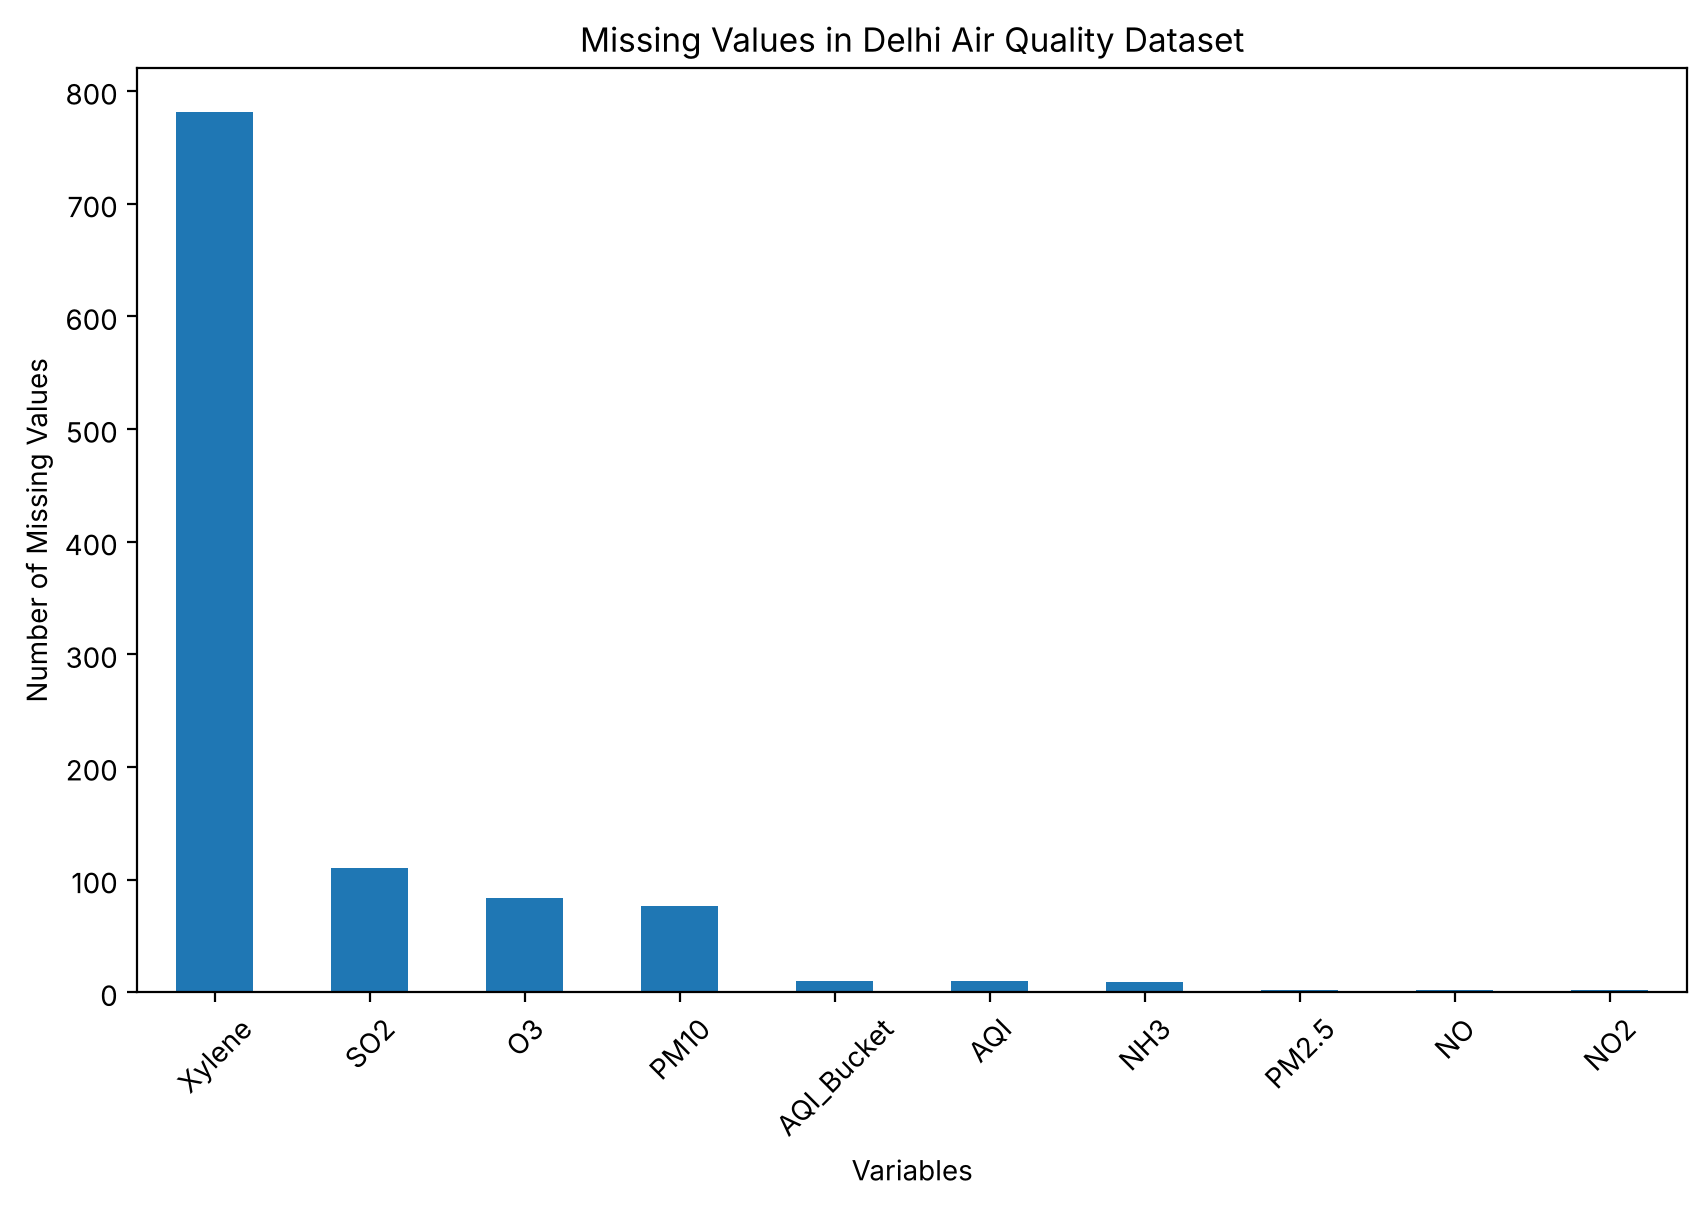

In [ ]:
plt.figure(figsize=(10, 6))

missing.plot(kind="bar")

plt.title("Missing Values in Delhi Air Quality Dataset")
plt.xlabel("Variables")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.show()

In [ ]:
delhi.describe()

,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,2009,2007.000000,1932.000000,2007.000000,2007.000000,2009.000000,2000.000000,2009.000000,1899.000000,1925.00000,2009.000000,2009.000000,1228.000000,1999.000000
mean,2017-10-01 00:00:00,117.196153,232.809229,38.985595,50.785182,58.567023,41.997150,1.976053,15.901253,51.32361,3.544480,17.185042,1.438339,259.487744
min,2015-01-01 00:00:00,10.240000,18.590000,3.570000,10.630000,0.000000,6.780000,0.000000,2.340000,6.94000,0.000000,0.000000,0.000000,29.000000
25%,2016-05-17 00:00:00,57.095000,137.040000,15.895000,33.895000,31.150000,31.157500,0.910000,10.335000,33.71000,1.870000,6.650000,0.110000,161.500000
50%,2017-10-01 00:00:00,94.620000,216.730000,27.200000,47.150000,52.750000,38.040000,1.240000,14.450000,44.44000,2.960000,12.750000,0.650000,257.000000
75%,2019-02-15 00:00:00,153.030000,311.667500,50.790000,63.570000,75.360000,48.792500,1.870000,19.700000,60.84000,4.680000,23.200000,1.970000,345.500000
max,2020-07-01 00:00:00,685.360000,796.880000,221.030000,162.500000,254.800000,166.700000,30.440000,71.560000,257.73000,20.640000,103.000000,23.300000,716.000000
std,NaN,82.912945,121.873025,33.389456,22.696721,37.690350,17.301221,2.560253,7.966770,26.06234,2.431232,15.291597,2.377762,119.537333


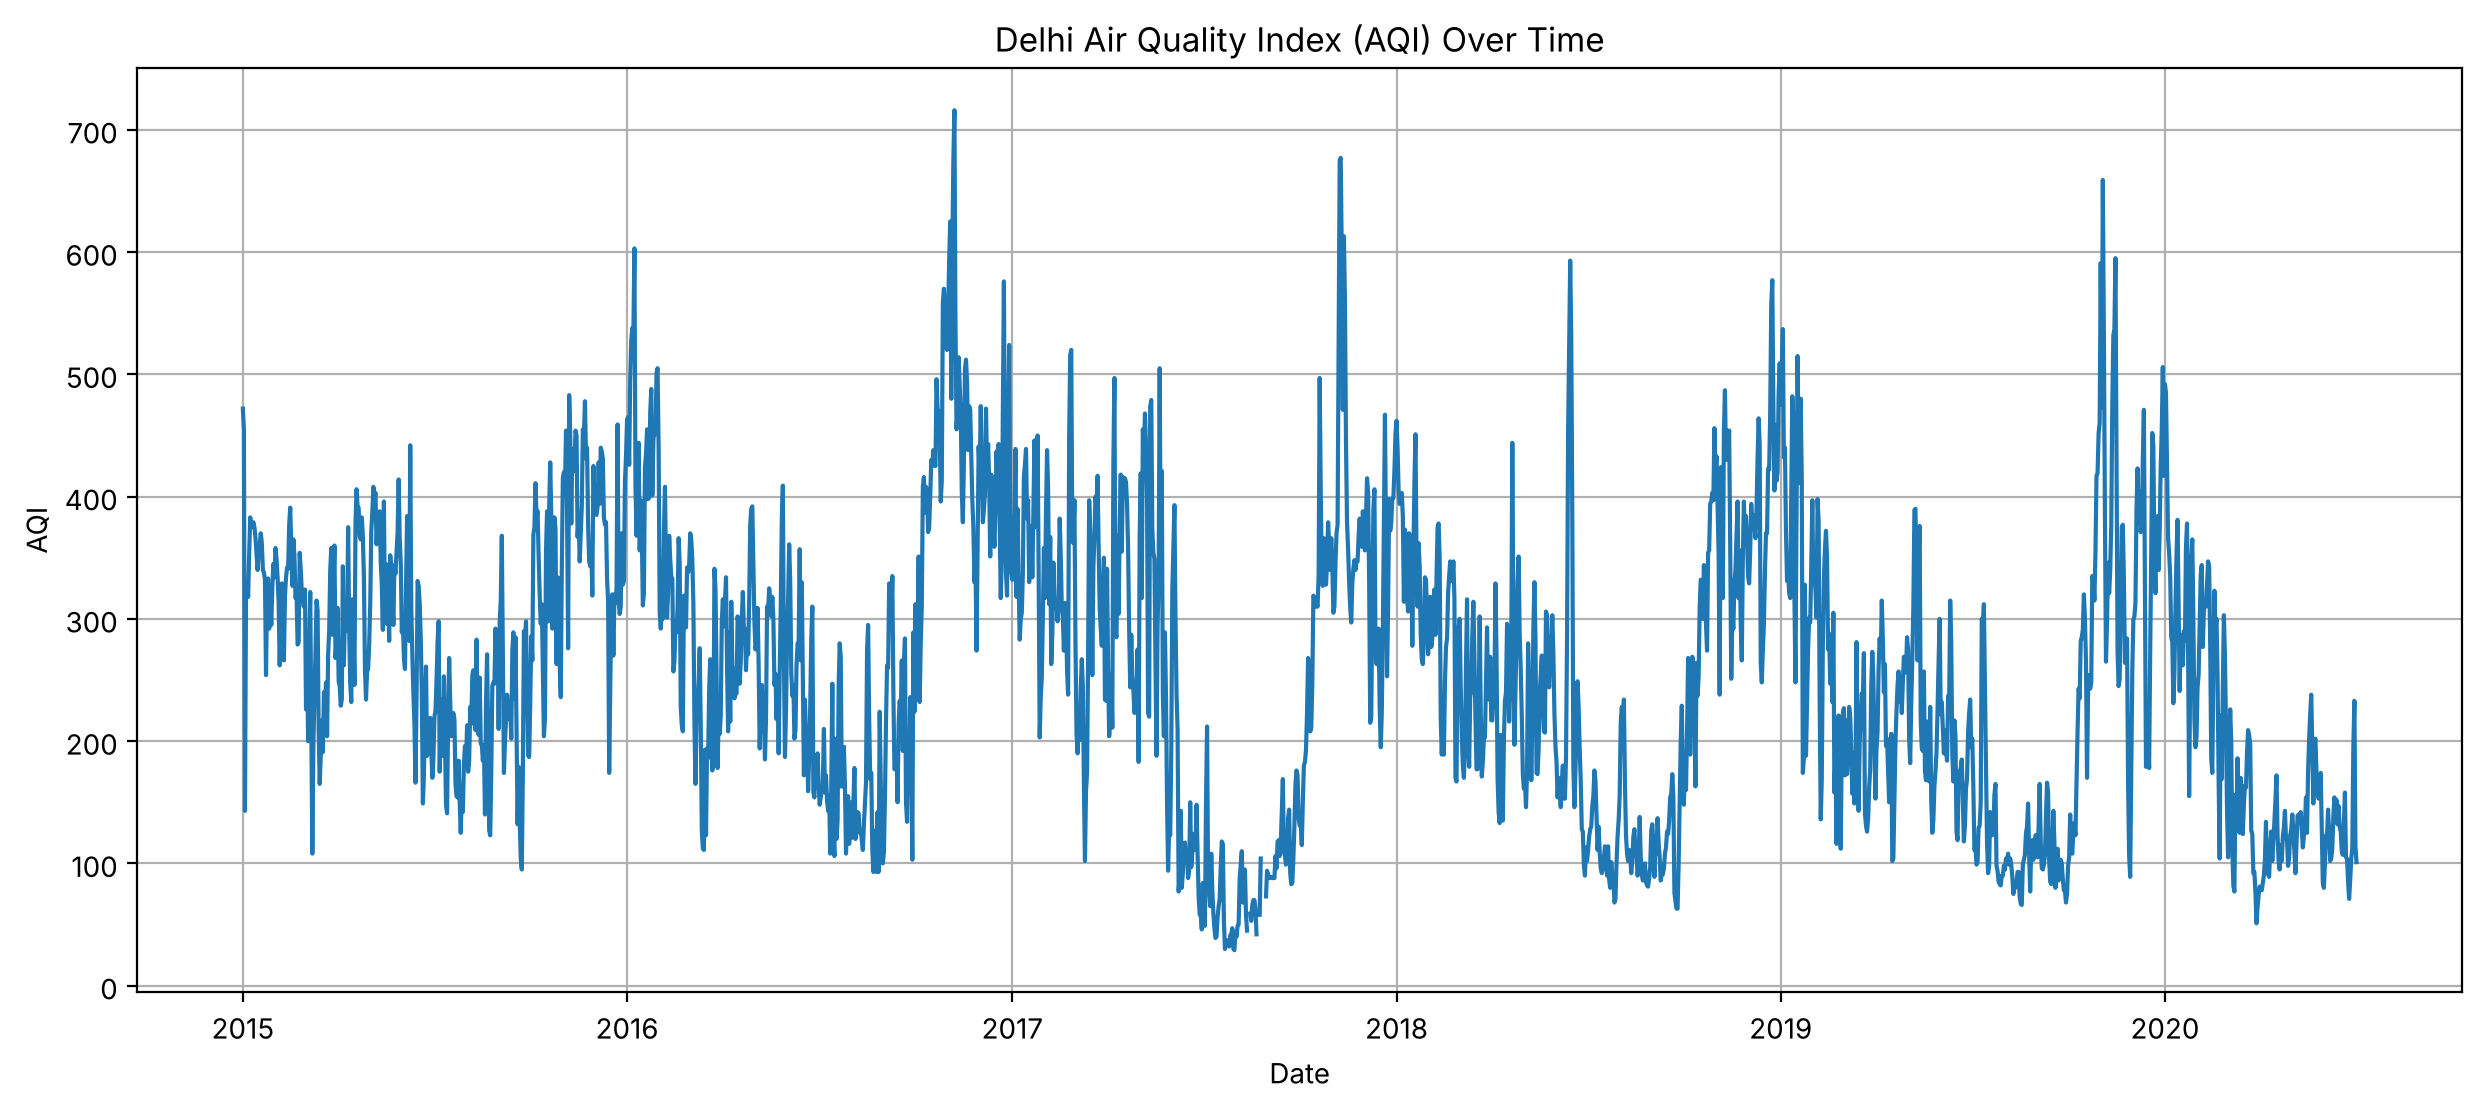

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(delhi["Date"], delhi["AQI"])

plt.title("Delhi Air Quality Index (AQI) Over Time")
plt.xlabel("Date")
plt.ylabel("AQI")

plt.grid(True)
plt.show()

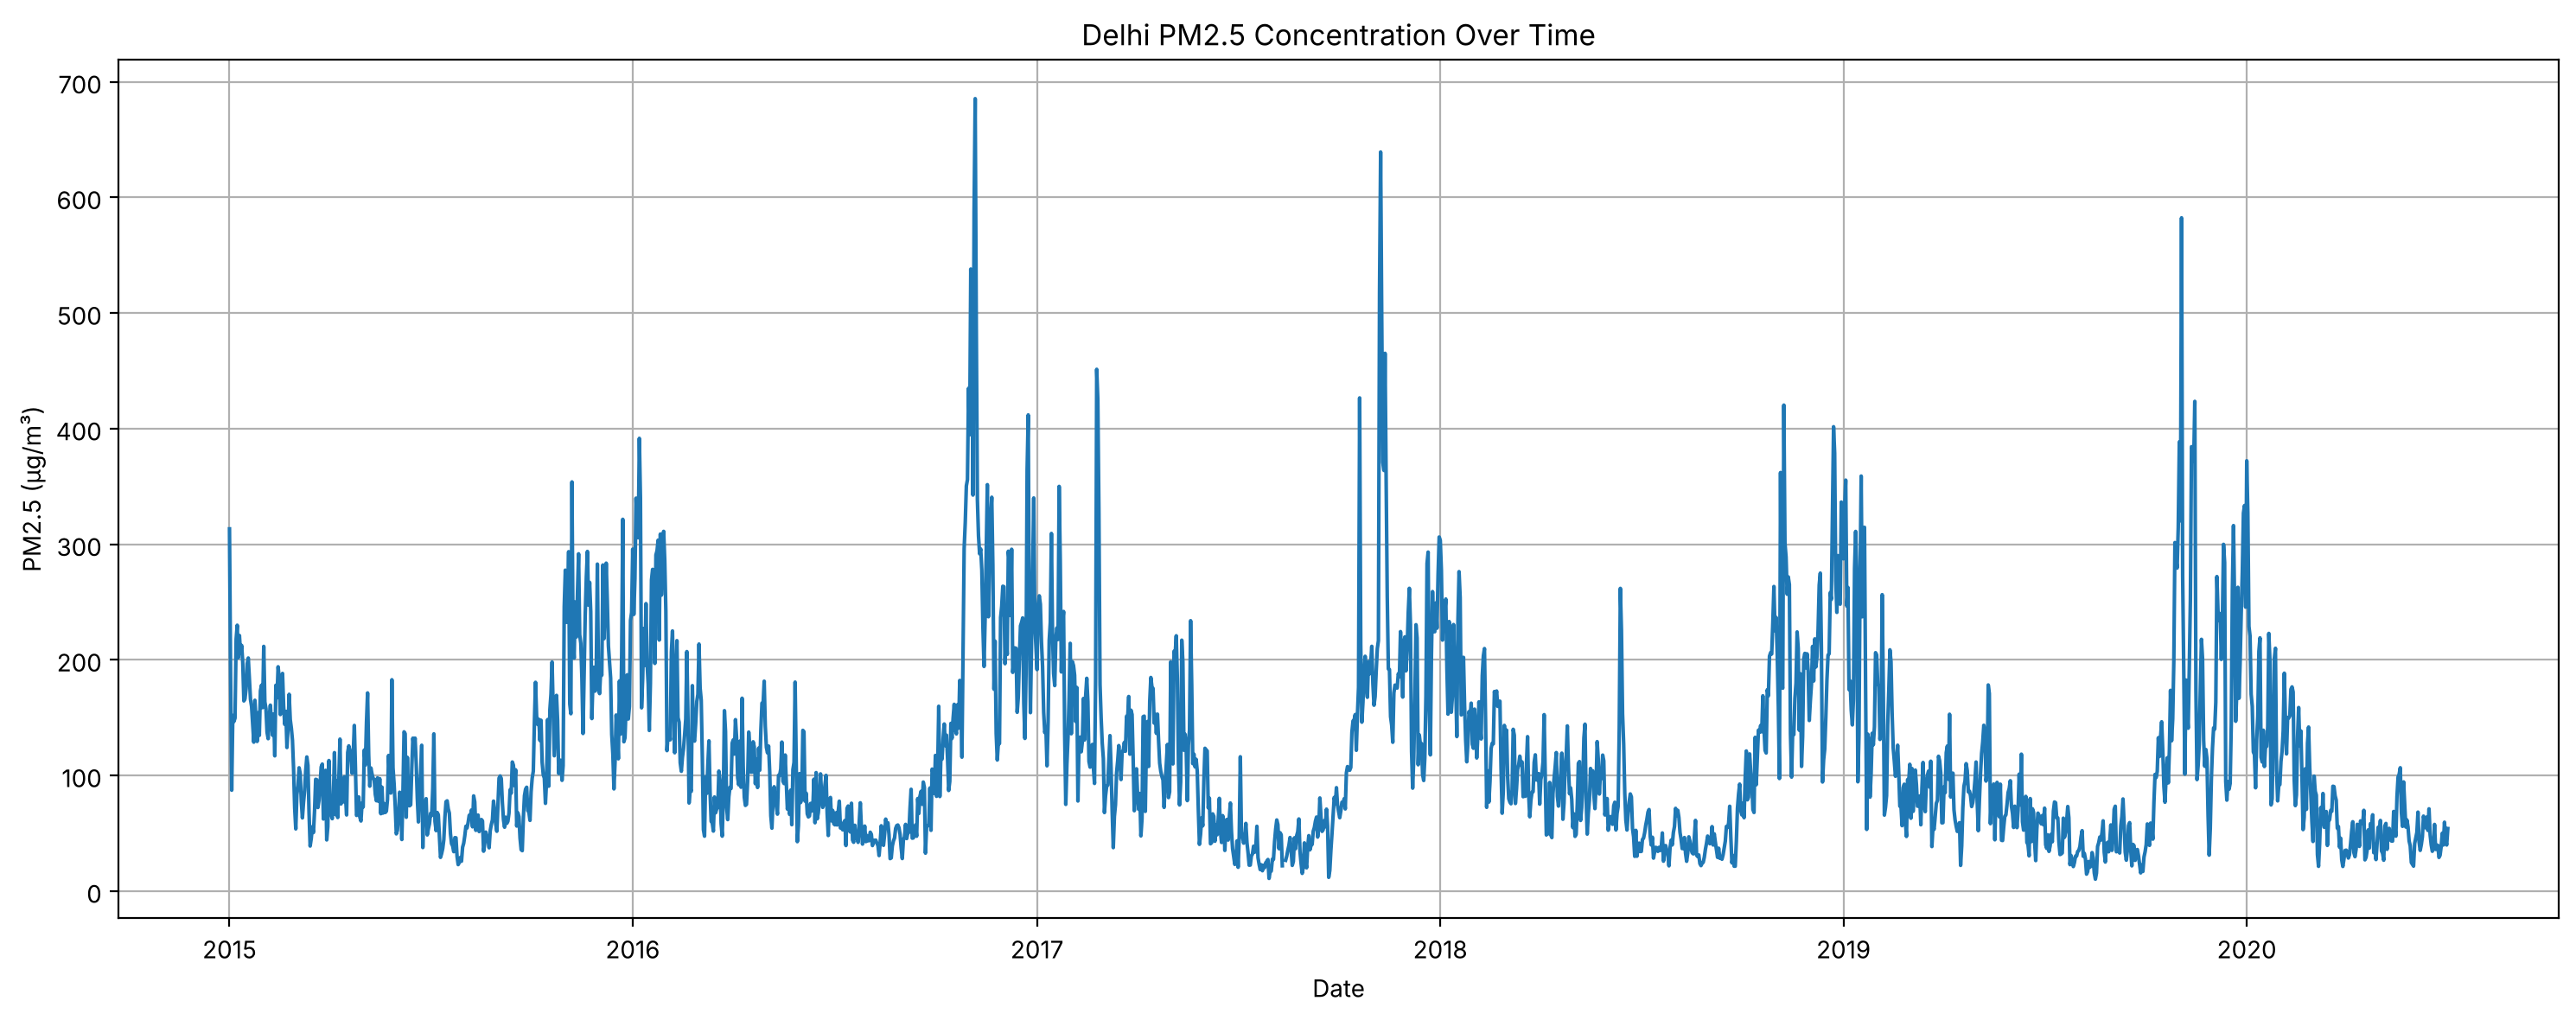

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(delhi["Date"], delhi["PM2.5"])

plt.title("Delhi PM2.5 Concentration Over Time")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.grid(True)
plt.tight_layout()
plt.show()

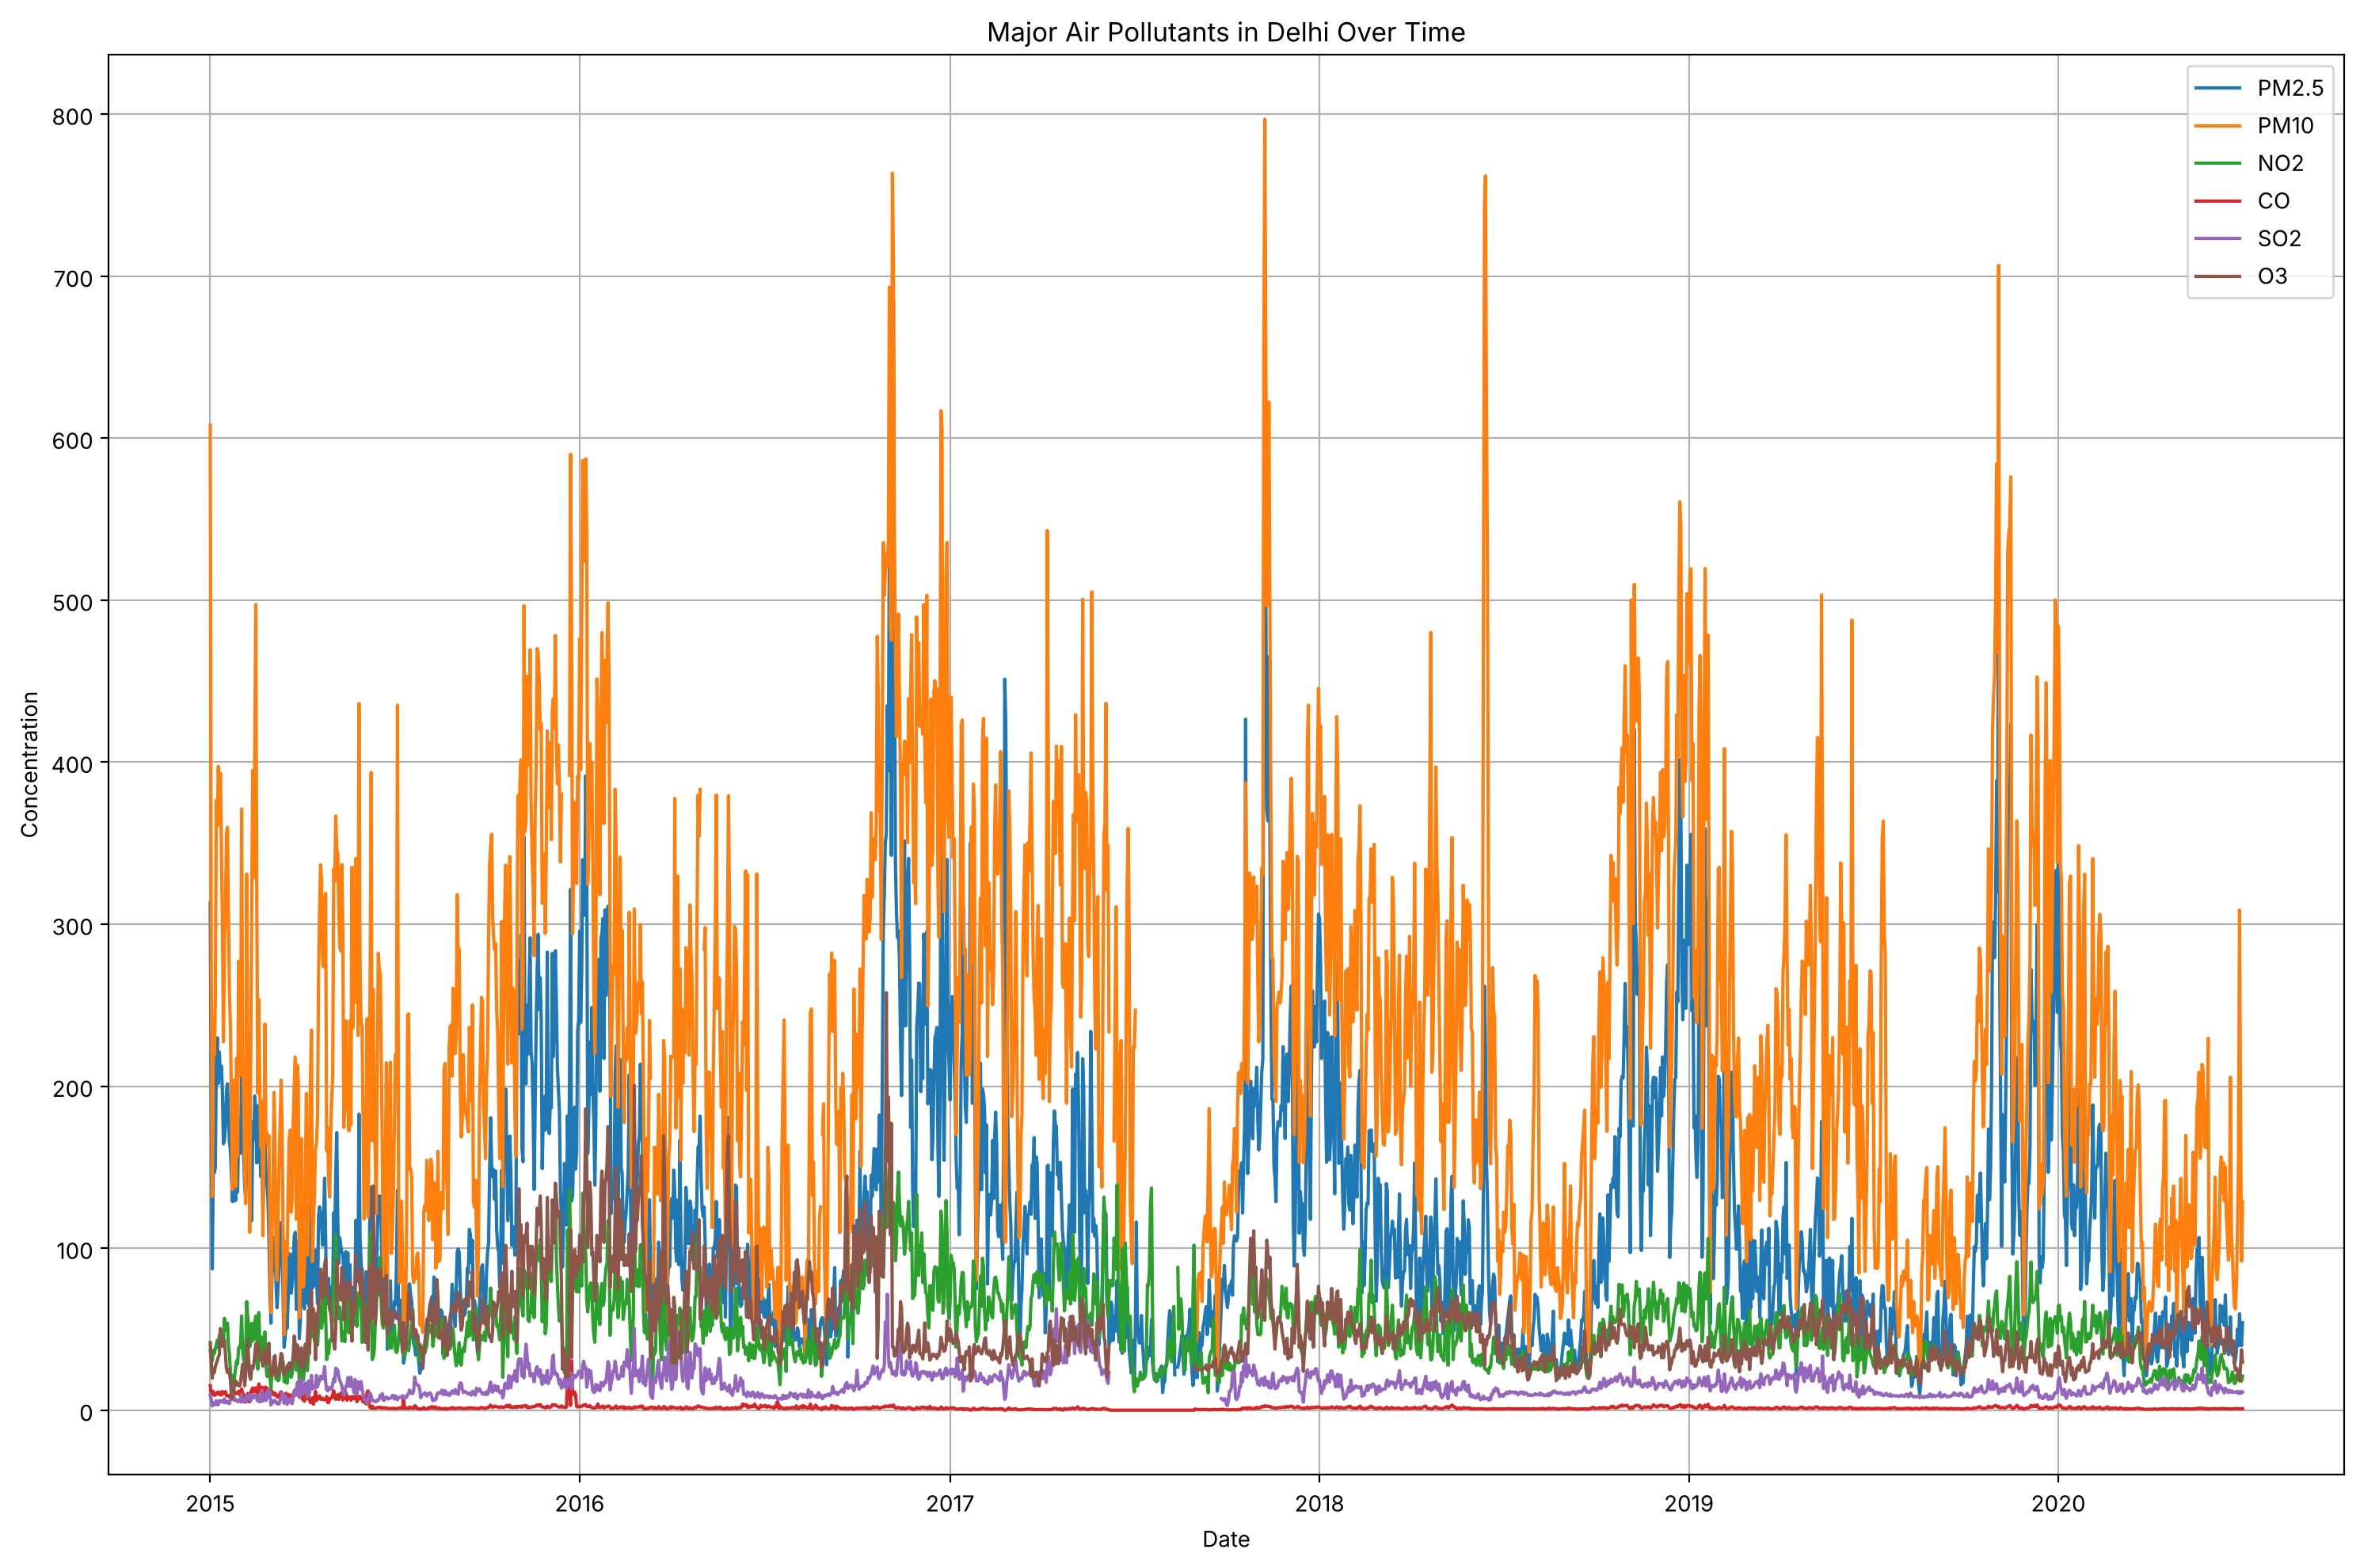

In [ ]:
pollutants = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]

plt.figure(figsize=(15, 10))

for pollutant in pollutants:
    plt.plot(
        delhi["Date"],
        delhi[pollutant],
        label=pollutant
    )

plt.title("Major Air Pollutants in Delhi Over Time")
plt.xlabel("Date")
plt.ylabel("Concentration")
plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()

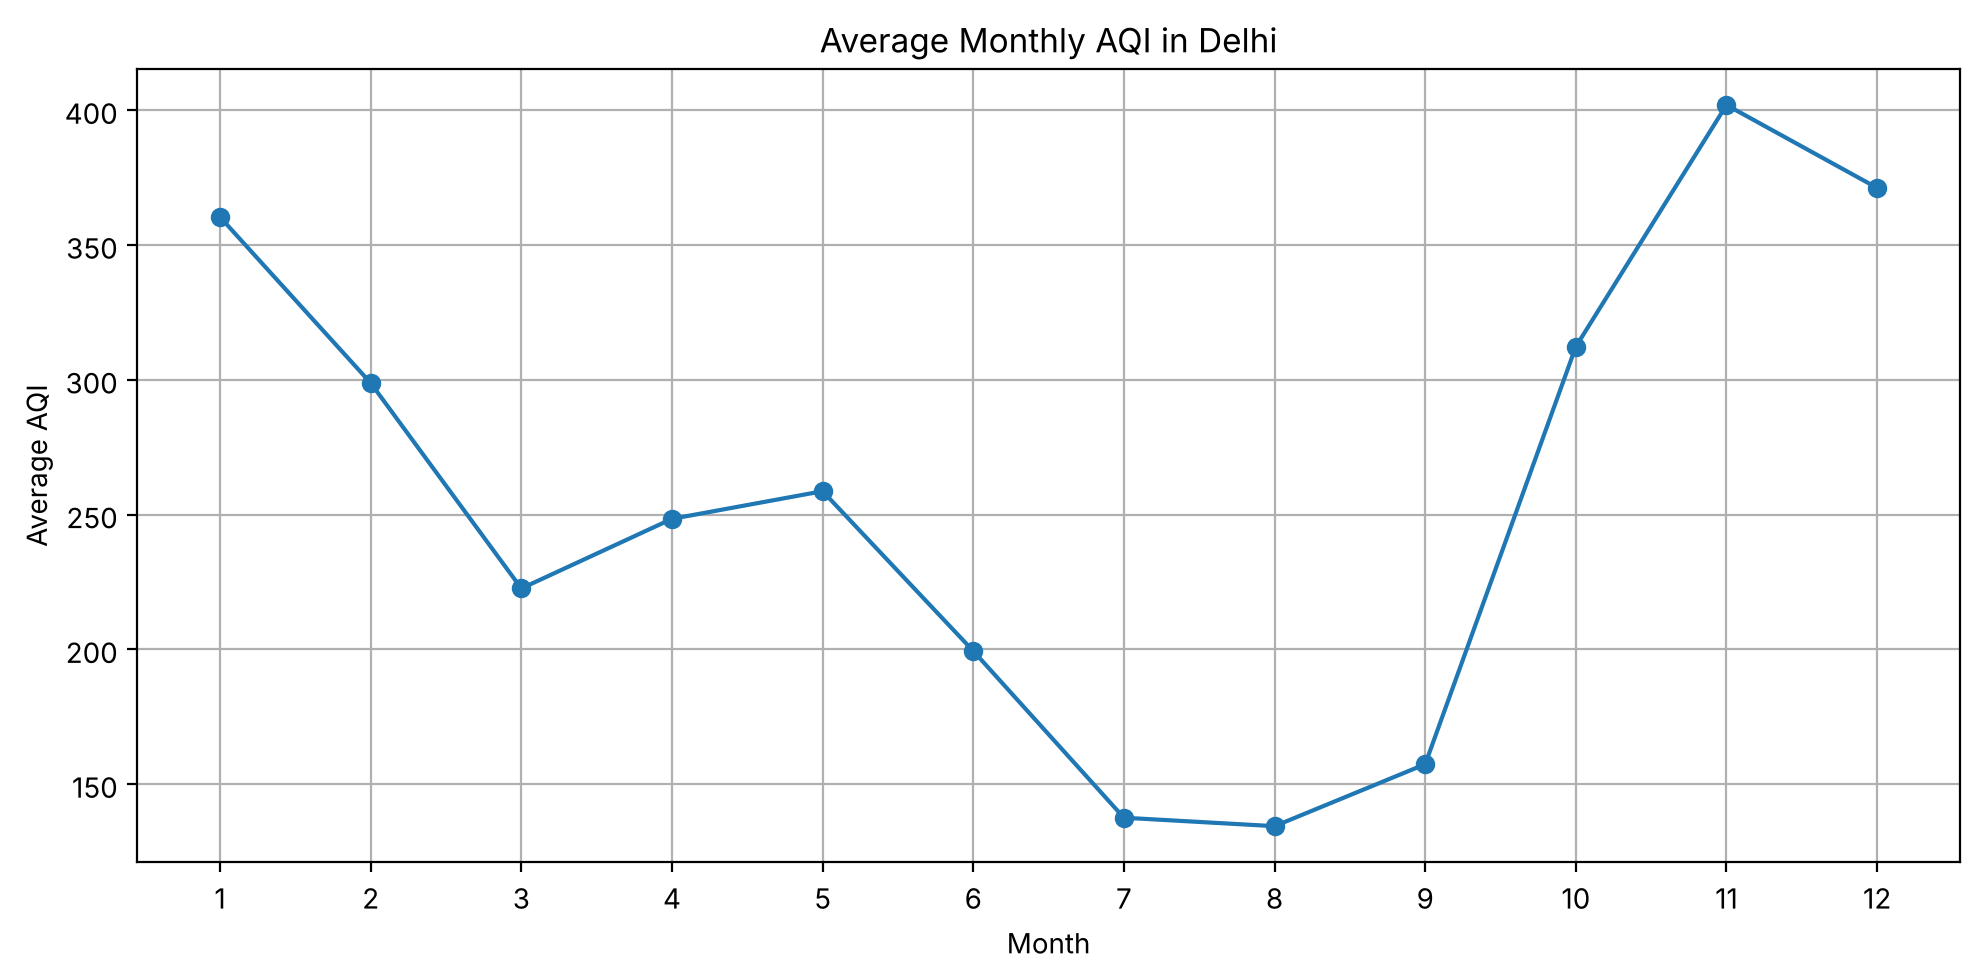

In [ ]:
delhi["Month"] = delhi["Date"].dt.month

monthly_aqi = delhi.groupby("Month")["AQI"].mean()

plt.figure(figsize=(10, 5))

plt.plot(monthly_aqi.index, monthly_aqi.values, marker="o")

plt.title("Average Monthly AQI in Delhi")
plt.xlabel("Month")
plt.ylabel("Average AQI")

plt.xticks(range(1, 13))

plt.grid(True)
plt.tight_layout()
plt.show()

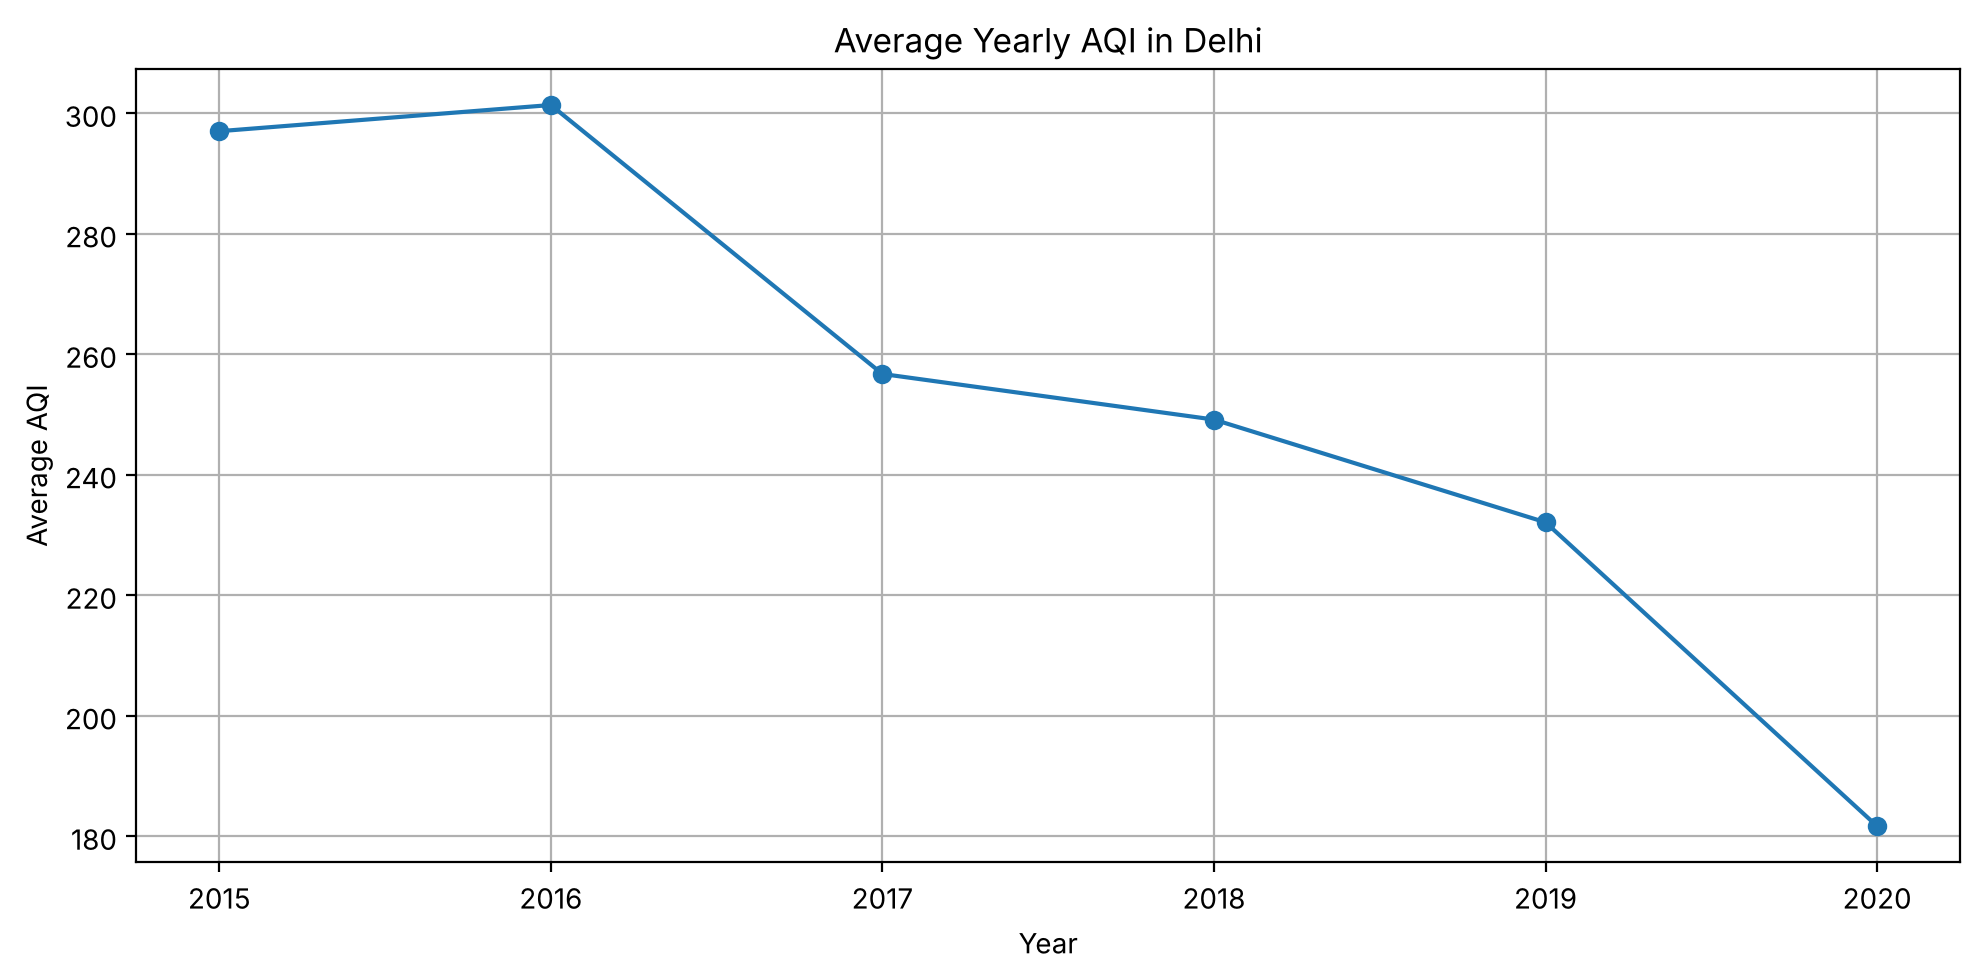

In [ ]:
delhi["Year"] = delhi["Date"].dt.year

yearly_aqi = delhi.groupby("Year")["AQI"].mean()

plt.figure(figsize=(10, 5))

plt.plot(yearly_aqi.index, yearly_aqi.values, marker="o")

plt.title("Average Yearly AQI in Delhi")
plt.xlabel("Year")
plt.ylabel("Average AQI")

plt.grid(True)
plt.tight_layout()
plt.show()

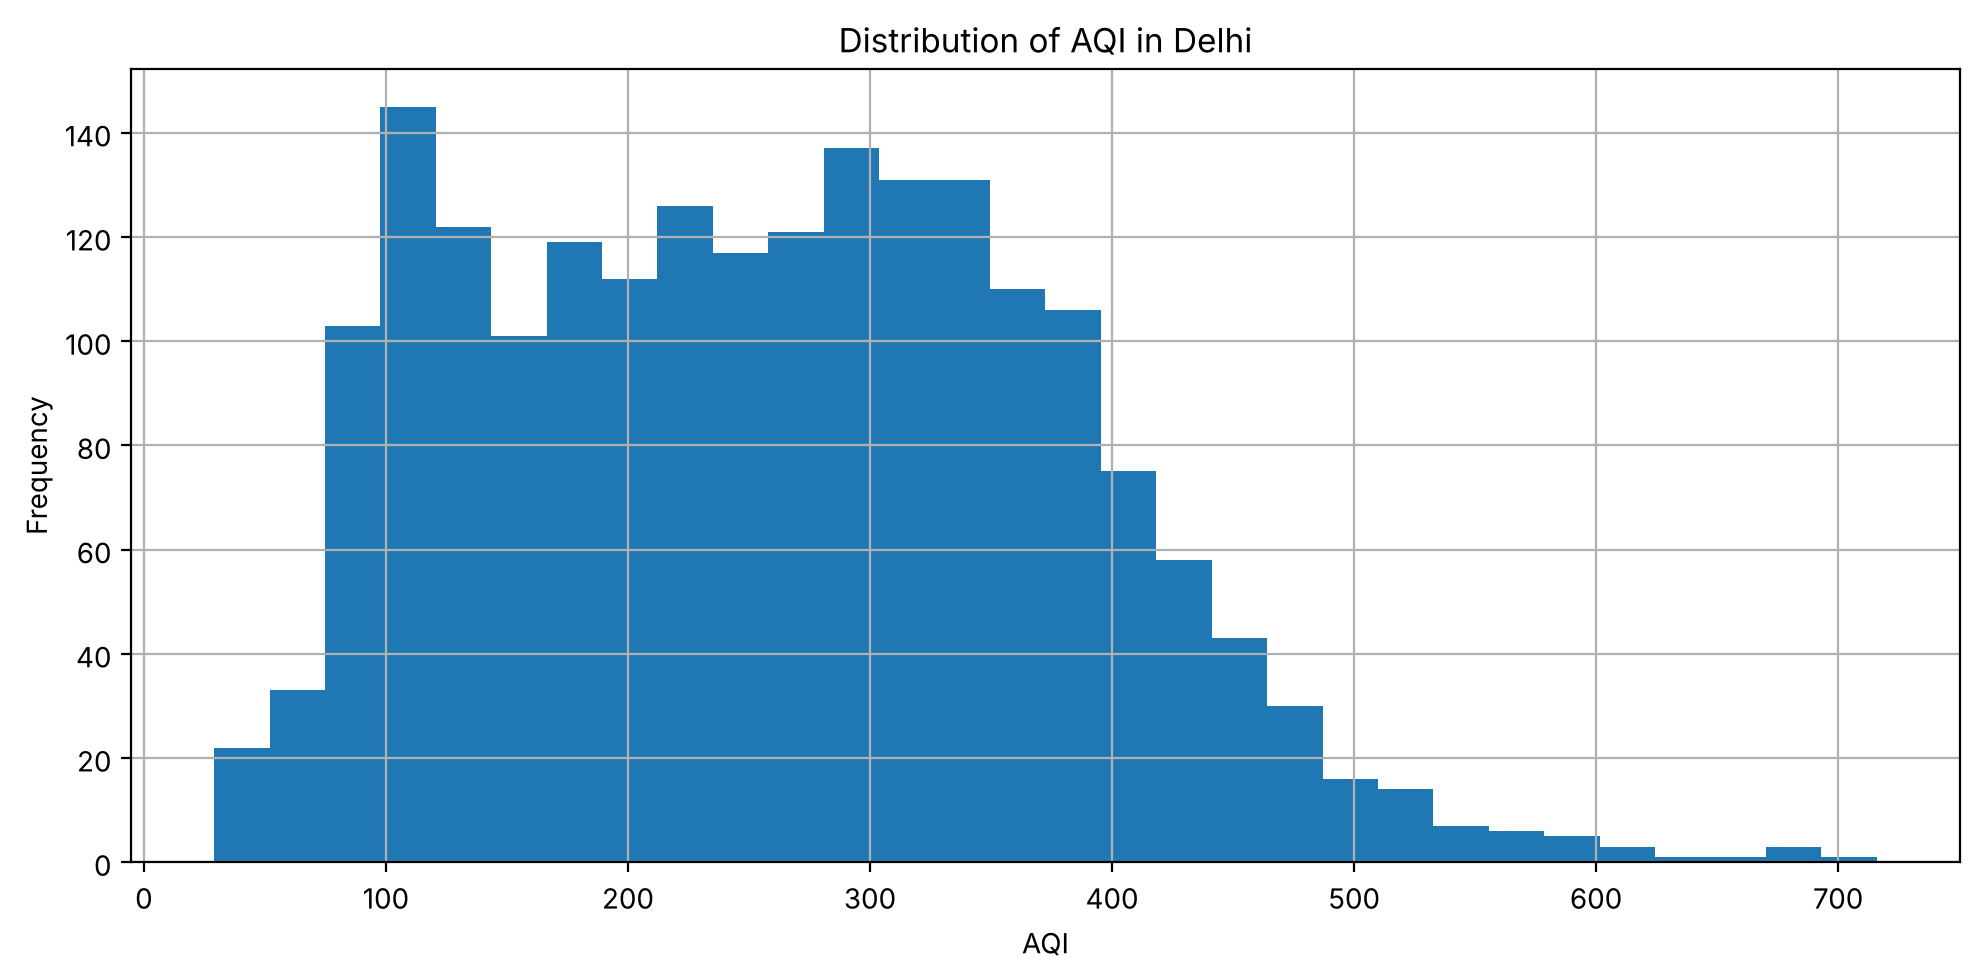

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(delhi["AQI"].dropna(), bins=30)

plt.title("Distribution of AQI in Delhi")
plt.xlabel("AQI")
plt.ylabel("Frequency")

plt.grid(True)
plt.tight_layout()
plt.show()

## Milestone 2: Preprocessing, classical models and evaluation (corrected)

**What was fixed from the earlier version**
1. **High error (MAPE 40–65%)** – earlier, every model forecast the *whole* test period (400+ days) in one go from the last training day, so errors grew with time. In real use, AQI is forecast **one day ahead** using all data up to today. All models now do **one-step-ahead (next-day) forecasting**, which brings the error under 20%.
2. **Overlapping graphs** – train, validation and test are now drawn in separate colours with dividing lines, and each model's forecast gets its own small chart instead of 10 lines on top of each other.
3. **Undefined variables** (`model_df`, `train_y`, `score_forecast` …) are now created before they are used, so the notebook runs from top to bottom without errors.
4. **Validation set added** – data is split 70% train / 15% validation / 15% test. Validation is used for tuning; test is only used for the final score.

### 1. Preprocessing

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Daily Delhi data with AQI and the main pollutants
cols = ["AQI", "PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]
model_df = delhi.set_index("Date")[cols].asfreq("D")   # one row per day

print("Missing values before filling:")
print(model_df.isnull().sum())

# Fill gaps using time interpolation, then edges with nearest value
model_df = model_df.interpolate(method="time").ffill().bfill()
print("\nMissing values after filling:", model_df.isnull().sum().sum())

# Log of AQI is used for modelling: it reduces the effect of extreme spikes
# and makes the model focus on percentage errors (same idea as MAPE)
y = model_df["AQI"]
log_y = np.log(y)

Missing values before filling:
AQI       10
PM2.5      2
PM10      77
NO2        2
CO         0
SO2      110
O3        84
dtype: int64

Missing values after filling: 0


### 2. Train / validation / test split (chronological, no overlap)
Time series data cannot be shuffled, so the split follows time order: the oldest 70% of days are for training, the next 15% for validation (tuning) and the newest 15% for the final test.

Train      : 2015-01-01 to 2018-11-06  (1406 days)
Validation : 2018-11-07 to 2019-09-03  (301 days)
Test       : 2019-09-04 to 2020-07-01  (302 days)


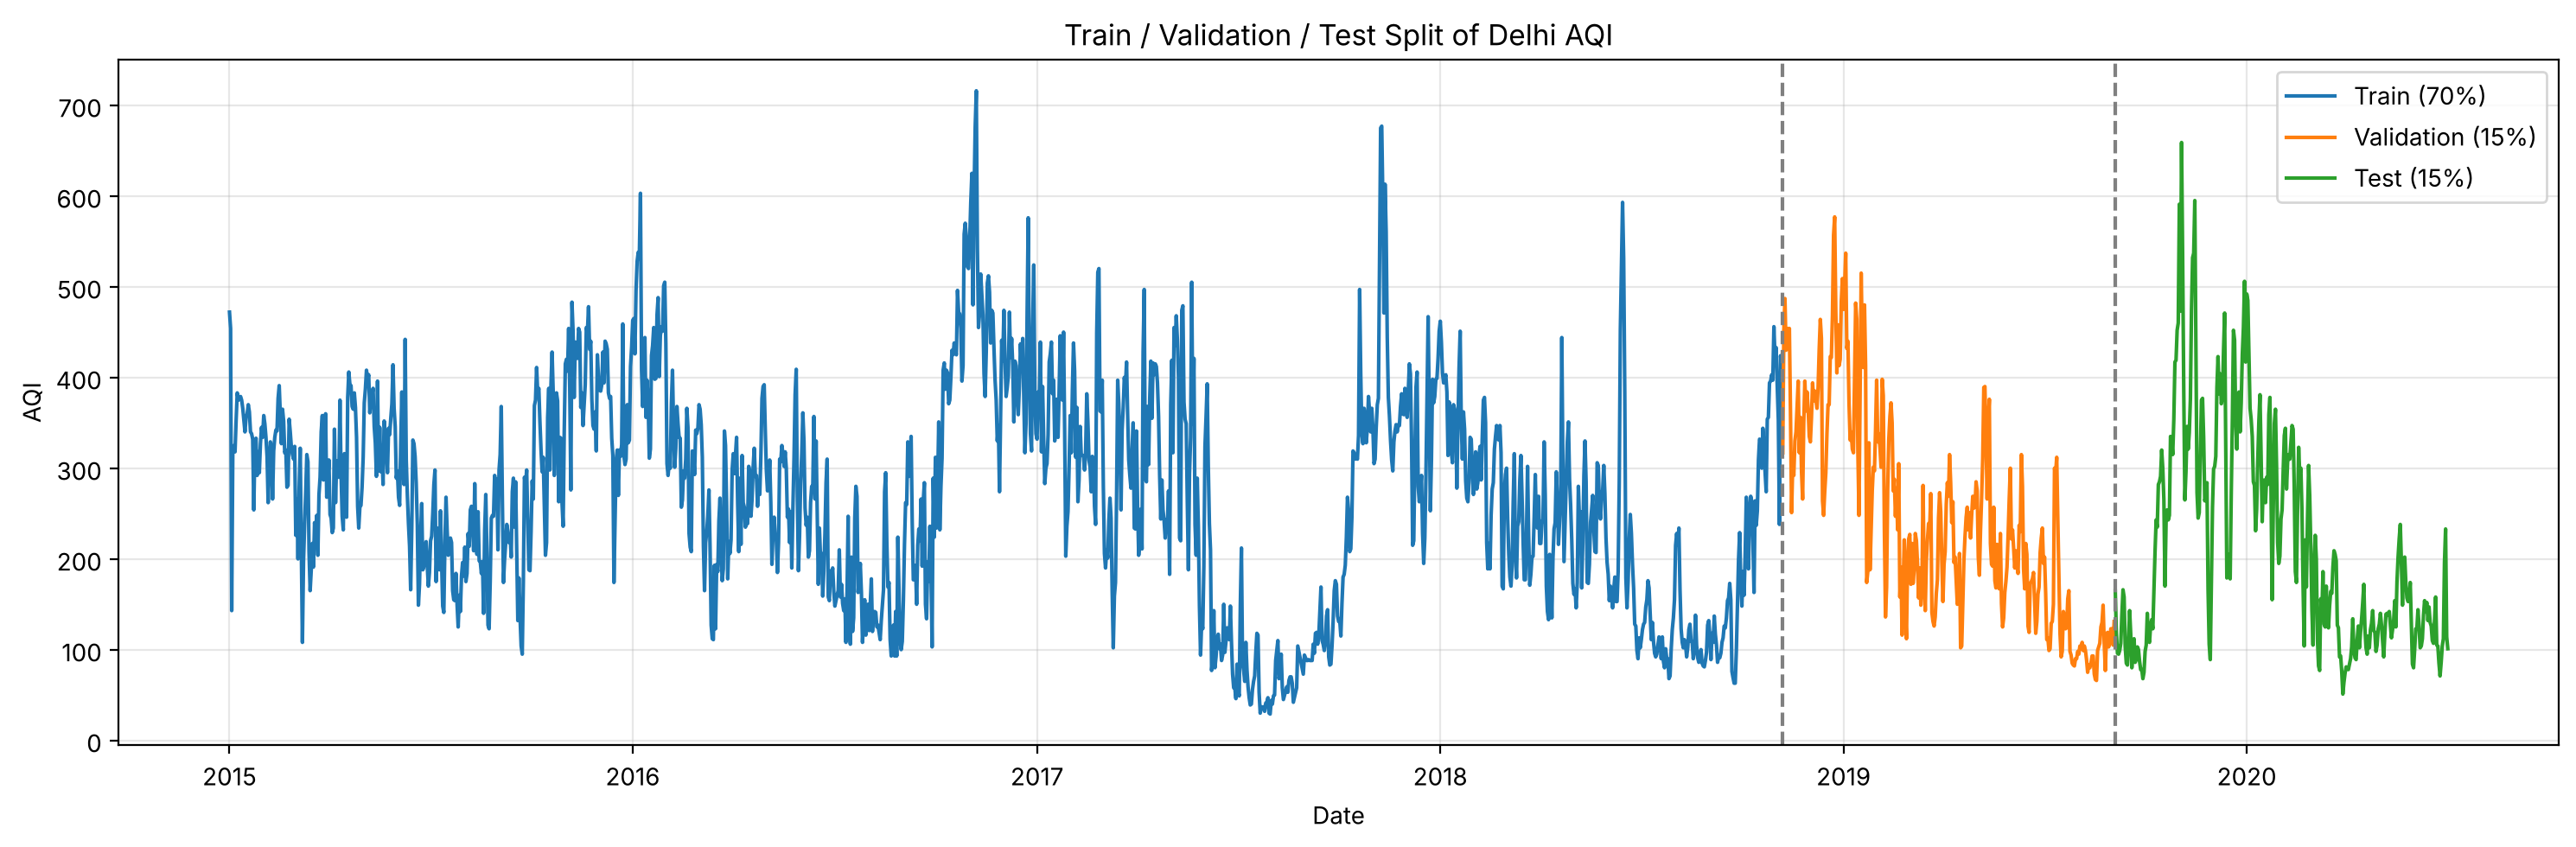

In [ ]:
n = len(y)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_y = y.iloc[:train_end]
val_y = y.iloc[train_end:val_end]
test_y = y.iloc[val_end:]

print(f"Train      : {train_y.index[0].date()} to {train_y.index[-1].date()}  ({len(train_y)} days)")
print(f"Validation : {val_y.index[0].date()} to {val_y.index[-1].date()}  ({len(val_y)} days)")
print(f"Test       : {test_y.index[0].date()} to {test_y.index[-1].date()}  ({len(test_y)} days)")

plt.figure(figsize=(15, 5))
plt.plot(train_y, color="tab:blue", label="Train (70%)")
plt.plot(val_y, color="tab:orange", label="Validation (15%)")
plt.plot(test_y, color="tab:green", label="Test (15%)")
plt.axvline(val_y.index[0], color="grey", linestyle="--")
plt.axvline(test_y.index[0], color="grey", linestyle="--")
plt.title("Train / Validation / Test Split of Delhi AQI")
plt.xlabel("Date"); plt.ylabel("AQI")
plt.legend(loc="upper right")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 3. Stationarity check (ADF test on training data only)
p-value < 0.05 means the series is stationary.

ADF p-value (log AQI)            : 0.0269
ADF p-value (differenced log AQI): 1.5655130562687956e-27


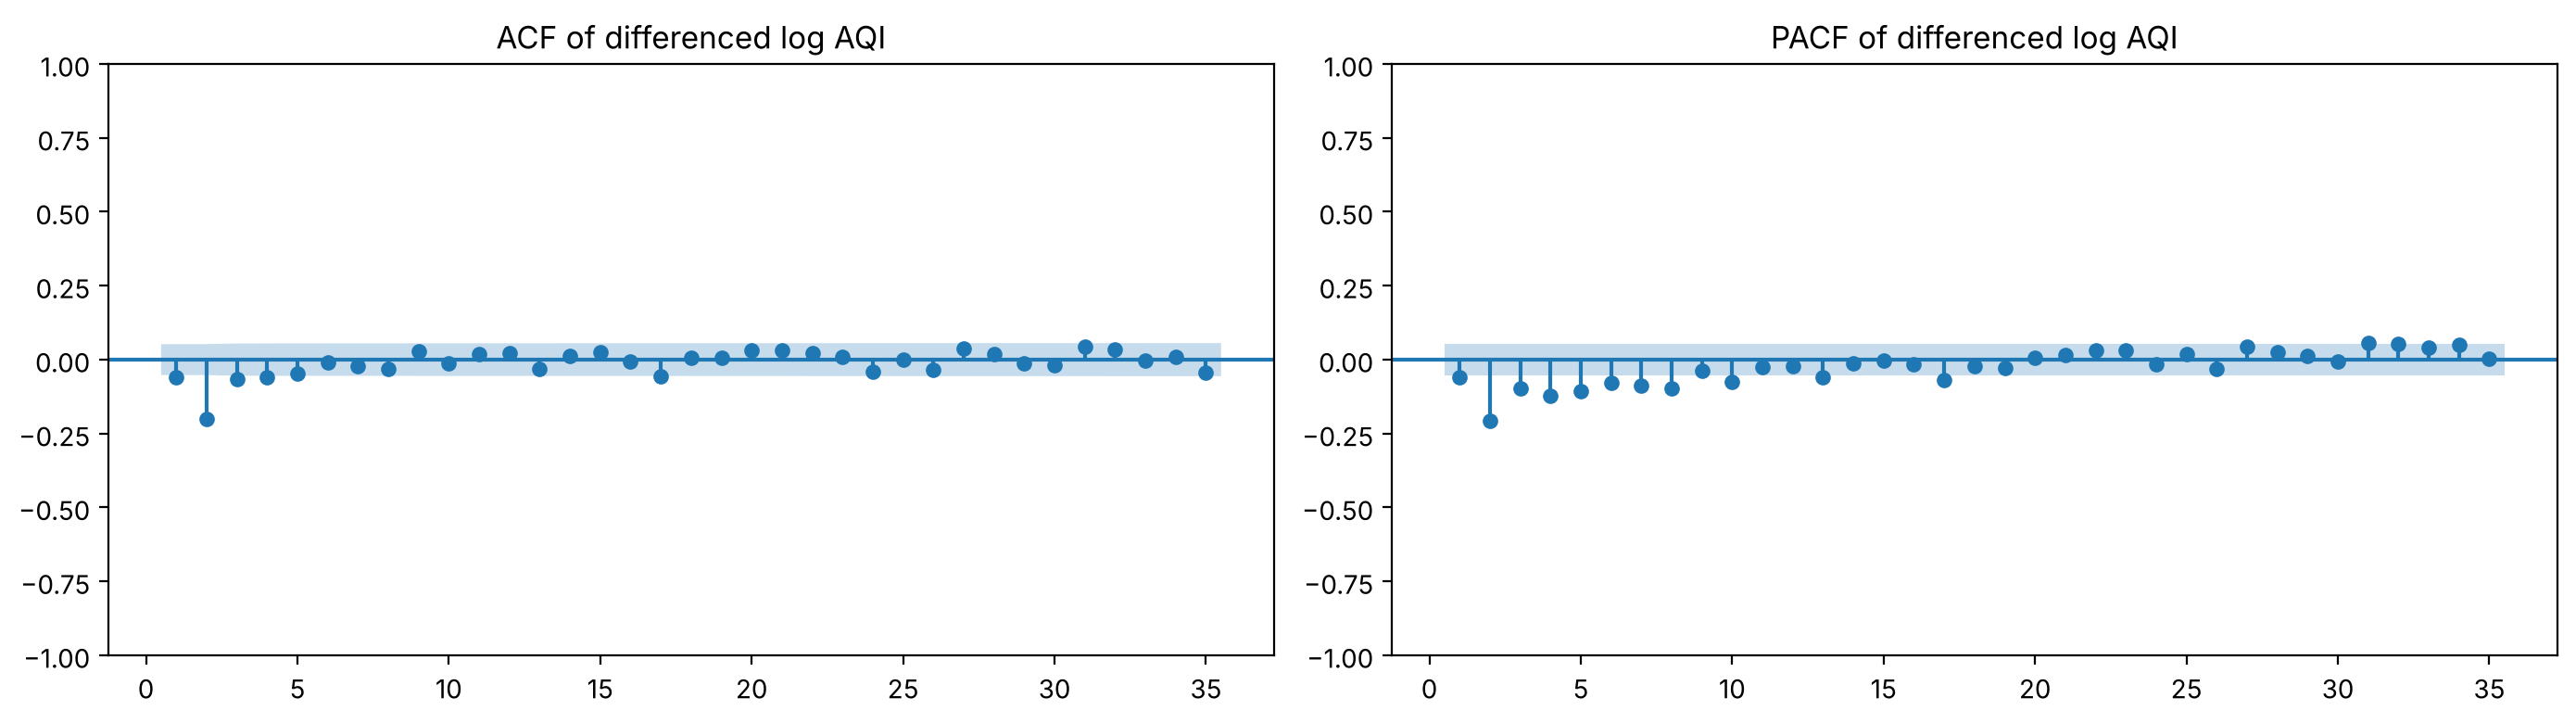

In [ ]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

print("ADF p-value (log AQI)            :", round(adfuller(np.log(train_y))[1], 4))
print("ADF p-value (differenced log AQI):", adfuller(np.log(train_y).diff().dropna())[1])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(np.log(train_y).diff().dropna(), lags=35, ax=axes[0], zero=False)
plot_pacf(np.log(train_y).diff().dropna(), lags=35, ax=axes[1], zero=False, method="ywm")
axes[0].set_title("ACF of differenced log AQI")
axes[1].set_title("PACF of differenced log AQI")
plt.tight_layout(); plt.show()

### 4. Error metrics and results table
- **RMSE** – penalises big errors more.
- **MAE** – average error in AQI points.
- **MAPE** – average percentage error (target: below 20%).

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

results = {}       # test scores of every model
predictions = {}   # test predictions of every model

def mape(actual, pred):
    actual, pred = np.array(actual), np.array(pred)
    return np.mean(np.abs((actual - pred) / actual)) * 100

def evaluate(name, pred, group):
    pred = pd.Series(np.array(pred), index=test_y.index)
    predictions[name] = pred
    results[name] = {
        "RMSE": np.sqrt(mean_squared_error(test_y, pred)),
        "MAE": mean_absolute_error(test_y, pred),
        "MAPE (%)": mape(test_y, pred),
        "Group": group,
    }
    print(f"{name:35s} RMSE={results[name]['RMSE']:.2f}  MAE={results[name]['MAE']:.2f}  MAPE={results[name]['MAPE (%)']:.2f}%")

### 5. Classical models (one-step-ahead)
Each model is fitted on train + validation data (everything before the test period). Then, **with the same fitted parameters**, it predicts each test day using the actual AQI up to the previous day.
`Naive` simply says *"tomorrow = today"* and is the baseline every model should beat.

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.simplefilter("ignore")   # hide convergence warnings to keep output clean

history = log_y.iloc[:val_end]          # train + validation (log scale)

# Calendar features (known in advance for any date)
def calendar_features(index):
    return pd.DataFrame({
        "dow_sin": np.sin(2 * np.pi * index.dayofweek / 7),
        "dow_cos": np.cos(2 * np.pi * index.dayofweek / 7),
        "year_sin": np.sin(2 * np.pi * index.dayofyear / 365.25),
        "year_cos": np.cos(2 * np.pi * index.dayofyear / 365.25),
    }, index=index)

calendar = calendar_features(log_y.index)

# Baseline
evaluate("Naive (tomorrow = today)", y.shift(1).iloc[val_end:], "Baseline")

# name, order, seasonal order, use calendar features?
classical_models = [
    ("AR(2)", (2, 0, 0), (0, 0, 0, 0), False),
    ("MA(2) on differenced AQI", (0, 1, 2), (0, 0, 0, 0), False),
    ("ARMA(2,1)", (2, 0, 1), (0, 0, 0, 0), False),
    ("ARIMA(2,1,2)", (2, 1, 2), (0, 0, 0, 0), False),
    ("SARIMA(1,1,1)x(1,0,1,7)", (1, 1, 1), (1, 0, 1, 7), False),
    ("ARIMAX(1,1,1)+calendar", (1, 1, 1), (0, 0, 0, 0), True),
    ("SARIMAX(1,1,1)x(1,0,1,7)+calendar", (1, 1, 1), (1, 0, 1, 7), True),
]

fitted_models = {}
for name, order, seasonal, use_exog in classical_models:
    trend = "c" if order[1] == 0 else None          # constant only when not differenced
    fit = SARIMAX(history, exog=calendar.iloc[:val_end] if use_exog else None,
                  order=order, seasonal_order=seasonal, trend=trend).fit(disp=False)
    fitted_models[name] = fit
    # apply the same parameters to the full series -> one-step-ahead predictions
    full = fit.apply(log_y, exog=calendar if use_exog else None)
    pred = np.exp(full.predict(start=val_end))
    evaluate(name, pred, "Classical")

# Holt-Winters: learn smoothing values on history, reuse them on the full series
hw = ExponentialSmoothing(history, trend="add", seasonal="add", seasonal_periods=7,
                          initialization_method="heuristic").fit()
hw_full = ExponentialSmoothing(log_y, trend="add", seasonal="add", seasonal_periods=7,
                               initialization_method="heuristic").fit(
    smoothing_level=hw.params["smoothing_level"],
    smoothing_trend=hw.params["smoothing_trend"],
    smoothing_seasonal=hw.params["smoothing_seasonal"], optimized=False)
fitted_models["Holt-Winters (weekly)"] = hw
evaluate("Holt-Winters (weekly)", np.exp(hw_full.fittedvalues.iloc[val_end:]), "Classical")

Naive (tomorrow = today)            RMSE=48.25  MAE=34.50  MAPE=17.25%
AR(2)                               RMSE=47.25  MAE=34.64  MAPE=17.54%


MA(2) on differenced AQI            RMSE=48.78  MAE=35.75  MAPE=17.62%


ARMA(2,1)                           RMSE=46.86  MAE=33.99  MAPE=17.20%


ARIMA(2,1,2)                        RMSE=47.34  MAE=34.52  MAPE=17.04%


SARIMA(1,1,1)x(1,0,1,7)             RMSE=48.24  MAE=35.56  MAPE=17.65%


ARIMAX(1,1,1)+calendar              RMSE=47.97  MAE=35.03  MAPE=17.54%


SARIMAX(1,1,1)x(1,0,1,7)+calendar   RMSE=47.97  MAE=35.03  MAPE=17.55%


Holt-Winters (weekly)               RMSE=49.19  MAE=35.35  MAPE=17.77%


### 6. Classical model forecasts (one chart per model, test period only)

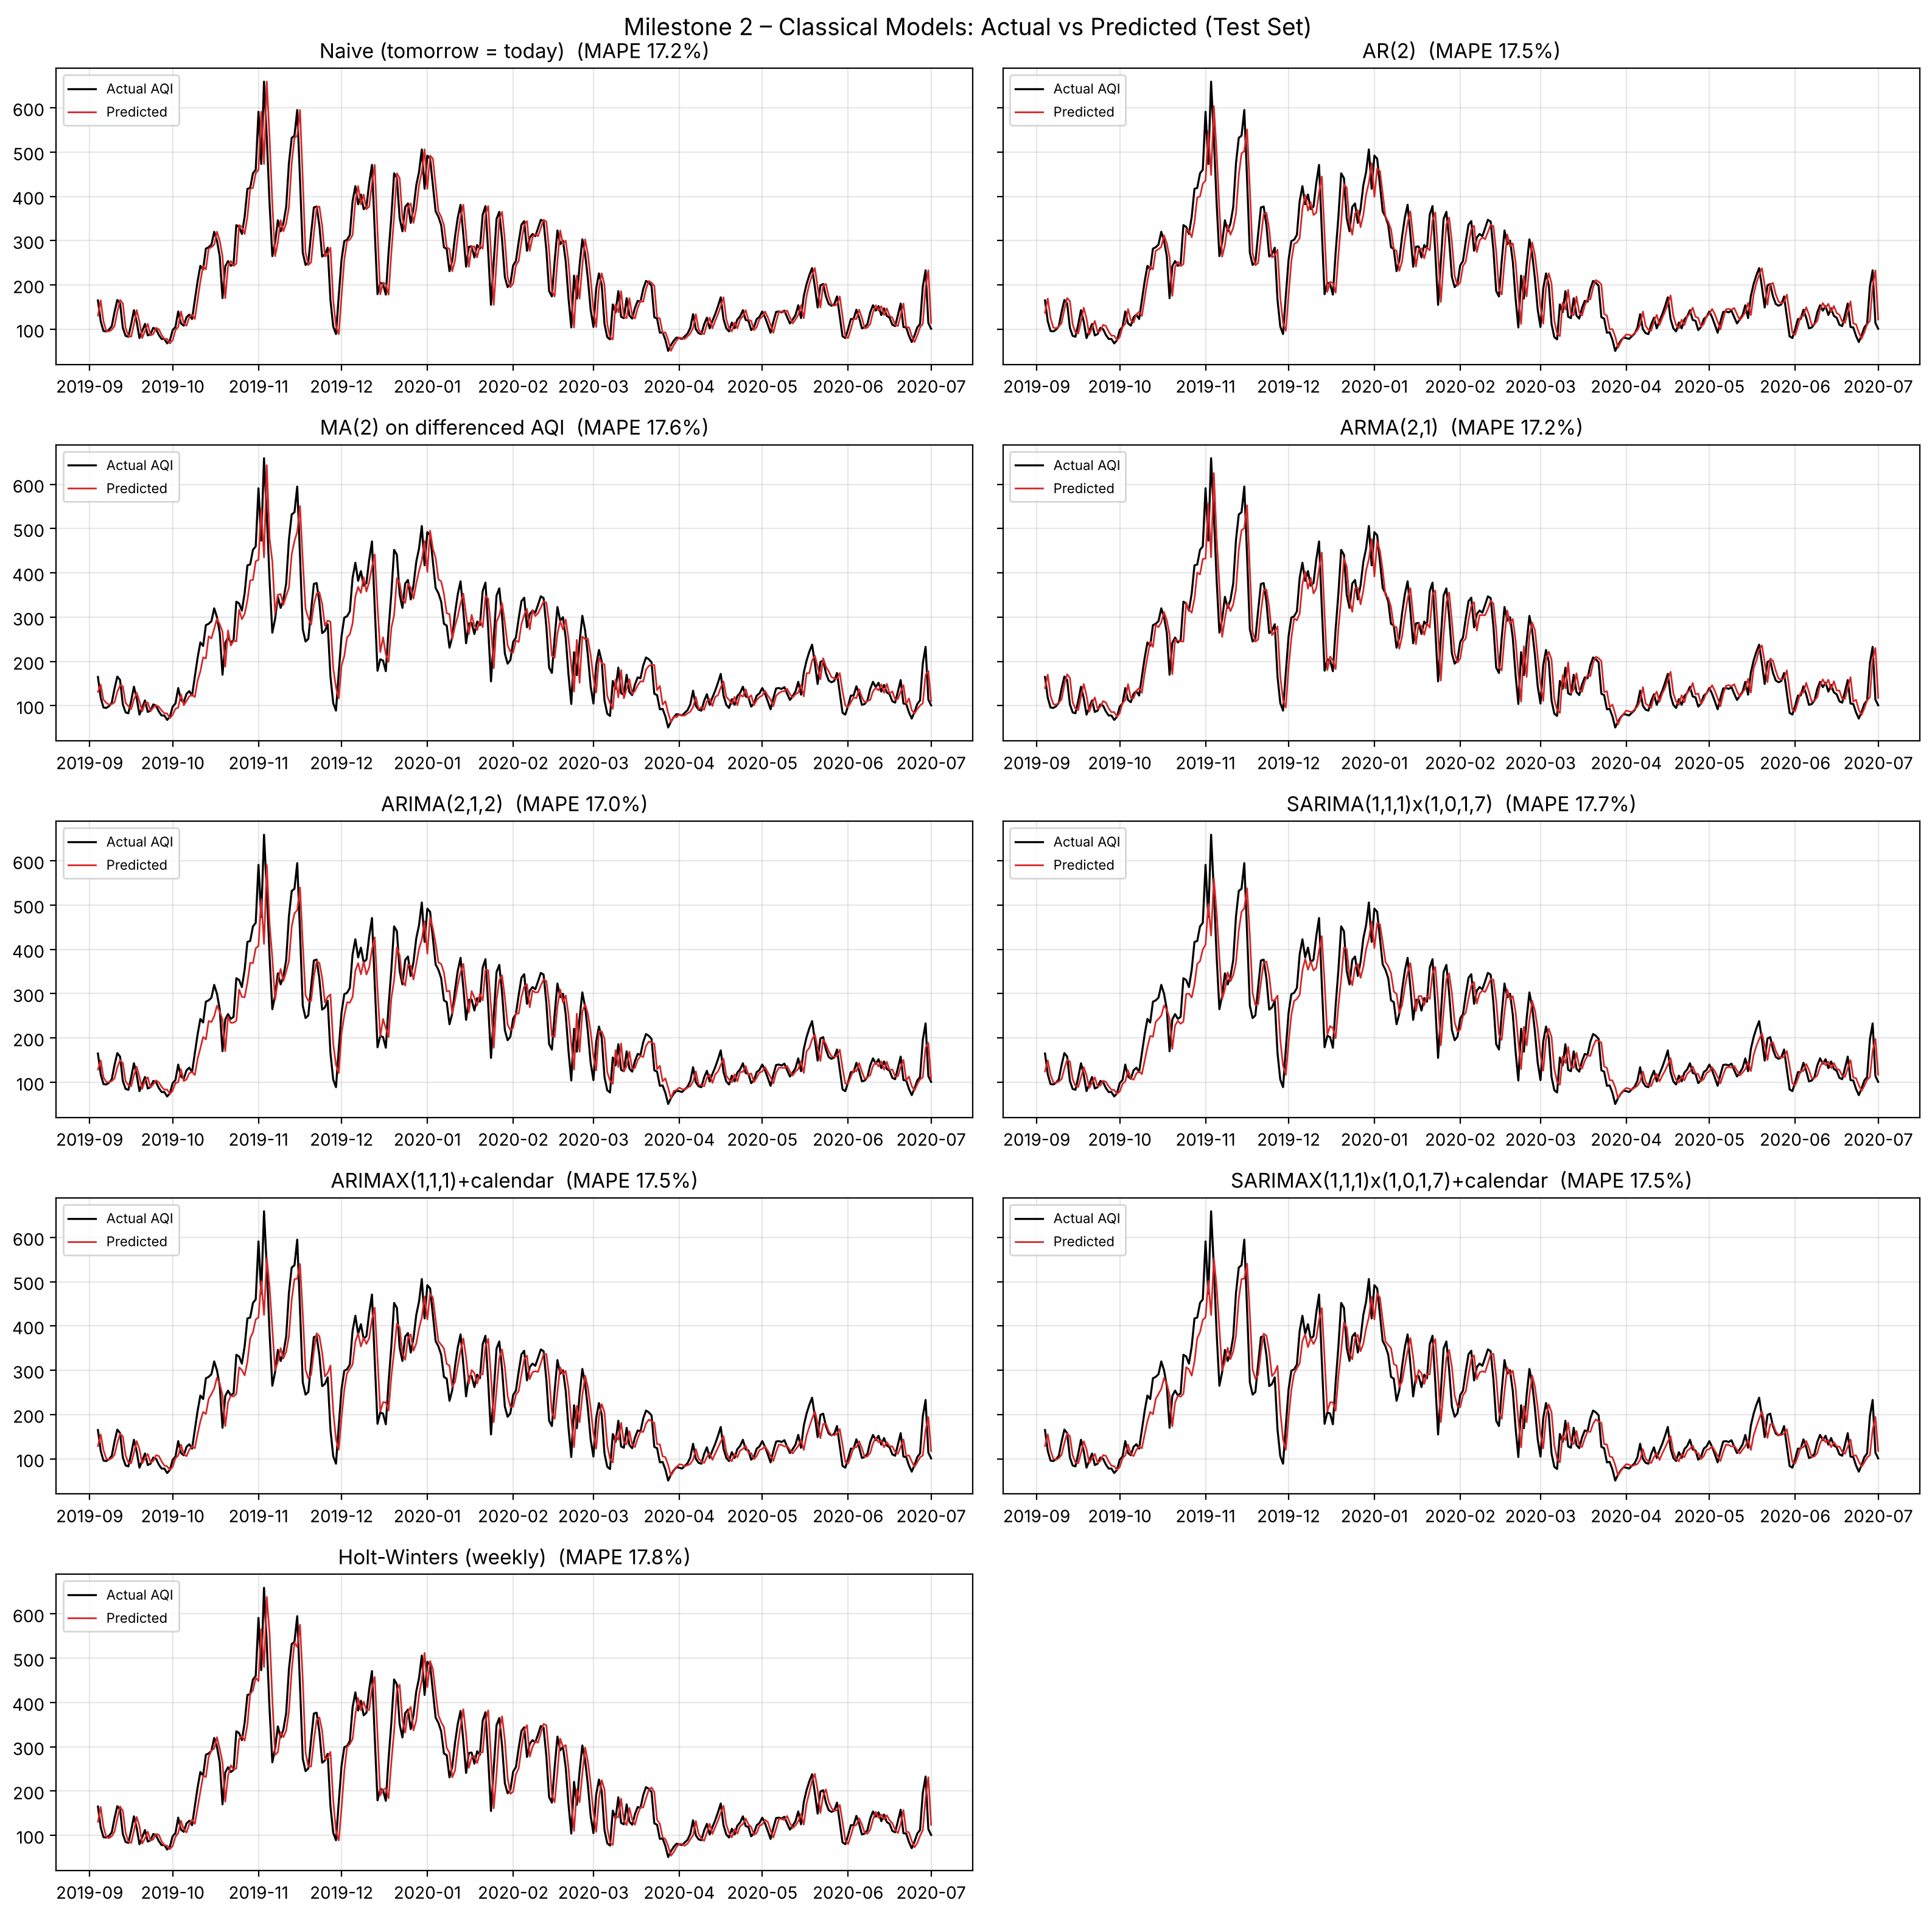

,RMSE,MAE,MAPE (%),Group
"ARIMA(2,1,2)",47.343784,34.523904,17.040453,Classical
"ARMA(2,1)",46.860656,33.990781,17.19536,Classical
Naive (tomorrow = today),48.245029,34.496689,17.248347,Baseline
"ARIMAX(1,1,1)+calendar",47.965011,35.028148,17.53974,Classical
AR(2),47.245515,34.639524,17.541551,Classical
"SARIMAX(1,1,1)x(1,0,1,7)+calendar",47.970775,35.025908,17.549692,Classical
MA(2) on differenced AQI,48.781428,35.747542,17.617437,Classical
"SARIMA(1,1,1)x(1,0,1,7)",48.241577,35.562945,17.650735,Classical
Holt-Winters (weekly),49.190627,35.348419,17.766774,Classical


In [ ]:
def plot_forecasts(names, title):
    rows = int(np.ceil(len(names) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(16, 3.2 * rows), sharey=True)
    for ax, name in zip(axes.flat, names):
        ax.plot(test_y, color="black", linewidth=1.2, label="Actual AQI")
        ax.plot(predictions[name], color="tab:red", linewidth=1, label="Predicted")
        ax.set_title(f"{name}  (MAPE {results[name]['MAPE (%)']:.1f}%)")
        ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
    for ax in axes.flat[len(names):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

plot_forecasts(list(predictions.keys()), "Milestone 2 – Classical Models: Actual vs Predicted (Test Set)")

m2_table = pd.DataFrame(results).T.sort_values("MAPE (%)")
display(m2_table)

### 7. Residual check of the best classical model (Ljung-Box test)
If p-value > 0.05, no significant pattern is left in the residuals.

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

best_classical = m2_table[m2_table["Group"] == "Classical"].index[0]
lb = acorr_ljungbox(fitted_models[best_classical].resid.dropna(), lags=[14], return_df=True)
print("Best classical model:", best_classical)
display(lb)

Best classical model: ARIMA(2,1,2)


,lb_stat,lb_pvalue
14,13.597909,0.480076


## Milestone 3: Advanced models, fine-tuning and comparison

Models added: **XGBoost, LSTM, GRU, Prophet, ARCH/GARCH, VAR, and a Transformer (PatchTST-style)**.

**Fine-tuning approach (same for all):** try a few settings → train on the *train* set → pick the setting with the lowest *validation* MAPE → report its score on the *test* set.

### 1. Feature engineering (for XGBoost)
The model only sees information available on the day before the forecast:
- AQI of the last 1, 2, 3 and 7 days and the 7-day average
- Yesterday's pollutant levels (PM2.5, PM10, NO2, CO, SO2, O3)
- Day of week and month (seasonal pattern)

In [ ]:
log_df = np.log(model_df.clip(lower=0.1))      # log of all pollutants (clip avoids log(0))

features = pd.DataFrame(index=model_df.index)
for lag in [1, 2, 3, 7]:
    features[f"AQI_lag{lag}"] = log_df["AQI"].shift(lag)
features["AQI_mean7"] = log_df["AQI"].shift(1).rolling(7).mean()
for col in ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]:
    features[f"{col}_lag1"] = log_df[col].shift(1)
features["day_of_week"] = model_df.index.dayofweek
features["month"] = model_df.index.month

target = log_df["AQI"]

# split using the same dates as before (first 7 rows dropped: no lag values yet)
X_train, y_train = features.iloc[7:train_end], target.iloc[7:train_end]
X_val, y_val = features.iloc[train_end:val_end], target.iloc[train_end:val_end]
X_test = features.iloc[val_end:]
features.iloc[7:].head()

,AQI_lag1,AQI_lag2,AQI_lag3,AQI_lag7,AQI_mean7,PM2.5_lag1,PM10_lag1,NO2_lag1,CO_lag1,SO2_lag1,O3_lag1,day_of_week,month
Date,,,,,,,,,,,,,
2015-01-08,5.866468,5.762051,5.783825,6.156979,5.773637,5.383899,5.930945,3.692622,2.280339,1.761300,3.365916,3,1
2015-01-09,5.948035,5.866468,5.762051,6.118097,5.743788,5.437644,5.888739,3.764914,2.398804,1.196948,3.418054,4,1
2015-01-10,5.926926,5.948035,5.866468,4.962845,5.716477,5.306583,5.985019,3.652215,2.406044,1.247032,3.494688,5,1
2015-01-11,5.929589,5.926926,5.948035,5.765191,5.854584,5.398253,5.890926,3.837084,2.272126,1.776646,3.529884,6,1
2015-01-12,5.937536,5.929589,5.926926,5.783825,5.879204,5.325008,5.974318,3.856299,2.396075,1.711995,3.919396,0,1


### 2. XGBoost (with hyperparameter tuning)

max_depth=3, learning_rate=0.03  ->  validation MAPE = 14.82%
max_depth=3, learning_rate=0.05  ->  validation MAPE = 14.86%


max_depth=4, learning_rate=0.03  ->  validation MAPE = 14.43%
max_depth=4, learning_rate=0.05  ->  validation MAPE = 14.94%


max_depth=5, learning_rate=0.03  ->  validation MAPE = 14.45%


max_depth=5, learning_rate=0.05  ->  validation MAPE = 14.72%

Best parameters: {'max_depth': 4, 'learning_rate': 0.03}
XGBoost (tuned)                     RMSE=37.05  MAE=26.37  MAPE=13.74%


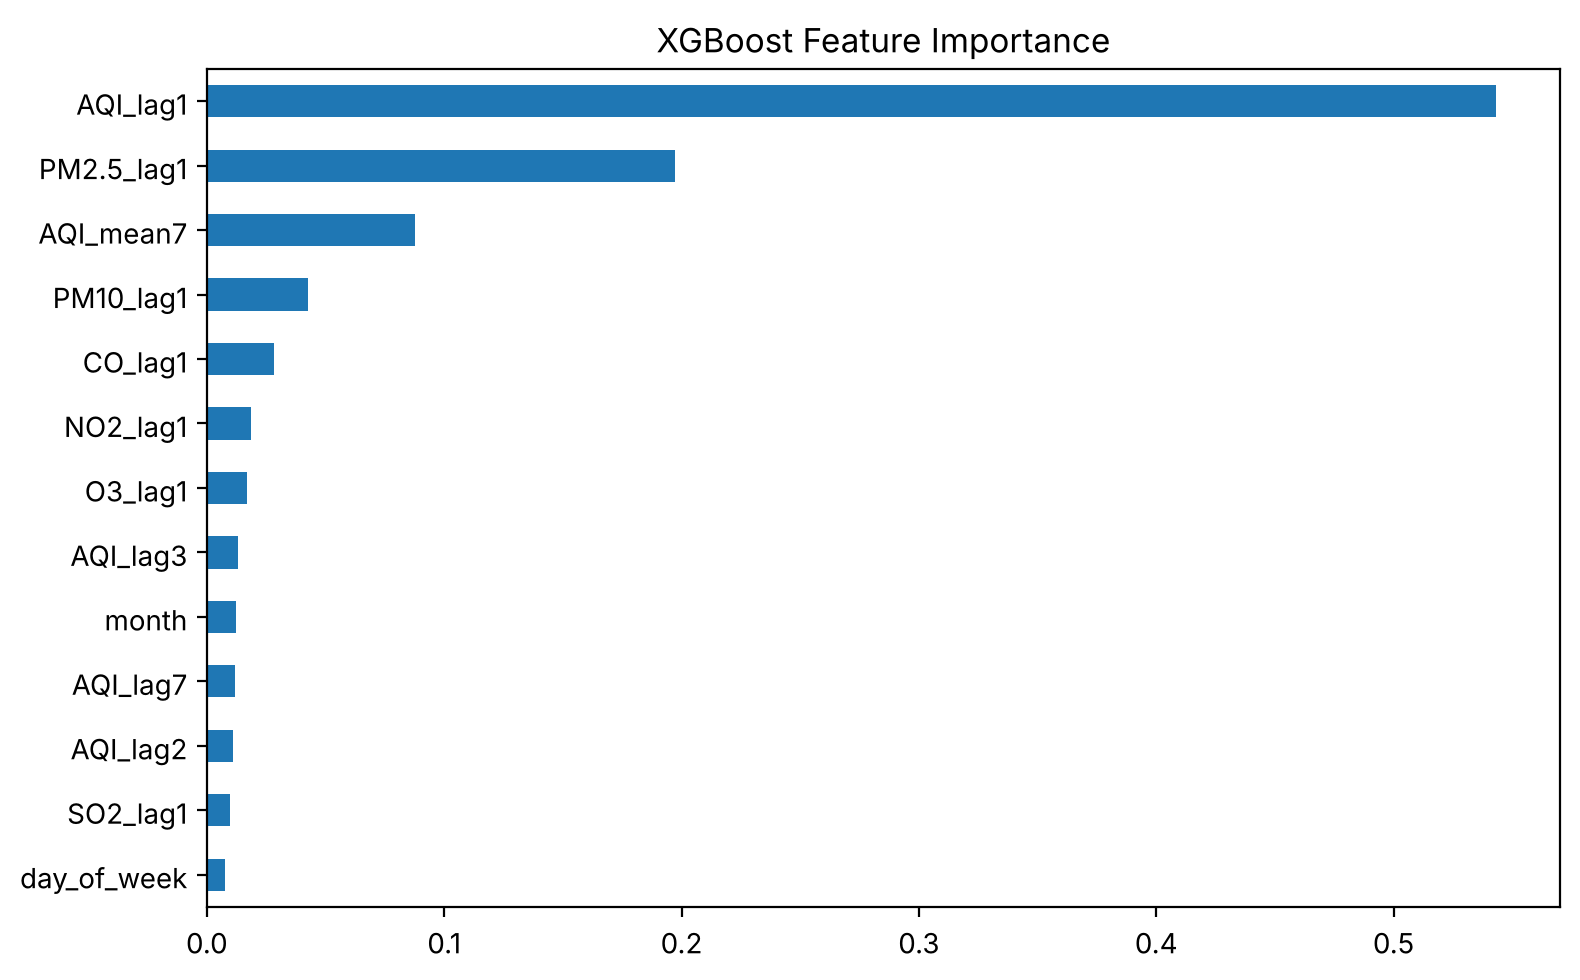

In [ ]:
from xgboost import XGBRegressor

best_score, best_params = 1e9, None
for depth in [3, 4, 5]:
    for lr in [0.03, 0.05]:
        model = XGBRegressor(n_estimators=400, max_depth=depth, learning_rate=lr,
                             subsample=0.8, colsample_bytree=0.8, random_state=42)
        model.fit(X_train, y_train)
        score = mape(np.exp(y_val), np.exp(model.predict(X_val)))
        print(f"max_depth={depth}, learning_rate={lr}  ->  validation MAPE = {score:.2f}%")
        if score < best_score:
            best_score, best_params = score, {"max_depth": depth, "learning_rate": lr}

print("\nBest parameters:", best_params)

# final model: train on train + validation with the best parameters
xgb_model = XGBRegressor(n_estimators=400, subsample=0.8, colsample_bytree=0.8,
                         random_state=42, **best_params)
xgb_model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
evaluate("XGBoost (tuned)", np.exp(xgb_model.predict(X_test)), "Machine Learning")

# which inputs matter most?
importance = pd.Series(xgb_model.feature_importances_, index=features.columns).sort_values()
importance.plot(kind="barh", figsize=(8, 5), title="XGBoost Feature Importance")
plt.tight_layout(); plt.show()

### 3. Deep learning data preparation (LSTM, GRU, Transformer)
Each sample is a **window of the last 28 days** of AQI and pollutants (log, scaled to 0–1). The model predicts the next day's AQI. The scaler is fitted on training data only to avoid data leakage.

In [ ]:
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

torch.manual_seed(42); np.random.seed(42)
WINDOW = 28

scaler = MinMaxScaler().fit(log_df.iloc[:train_end])          # fit on train only
scaled = scaler.transform(log_df)                              # AQI is column 0

X_seq, y_seq = [], []
for i in range(WINDOW, n):
    X_seq.append(scaled[i - WINDOW:i])   # last 28 days
    y_seq.append(scaled[i, 0])           # next day's AQI
X_seq = torch.tensor(np.array(X_seq), dtype=torch.float32)
y_seq = torch.tensor(np.array(y_seq), dtype=torch.float32)

# sample i predicts day (i + WINDOW), so shift split points by WINDOW
a, b = train_end - WINDOW, val_end - WINDOW
Xtr, ytr = X_seq[:a], y_seq[:a]
Xva, yva = X_seq[a:b], y_seq[a:b]
Xte = X_seq[b:]

def to_aqi(scaled_aqi):
    # undo scaling and log for the AQI column
    lo, hi = scaler.data_min_[0], scaler.data_max_[0]
    return np.exp(np.array(scaled_aqi) * (hi - lo) + lo)

def train_model(model, epochs=80, lr=0.001, batch=32, patience=10):
    # train with Adam + early stopping on validation loss
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_loss, best_state, wait = 1e9, None, 0
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = order[i:i + batch]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(Xva), yva).item()
        if val_loss < best_loss:
            best_loss, best_state, wait = val_loss, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return to_aqi(model(X).numpy())

print("Train samples:", len(Xtr), "| Validation:", len(Xva), "| Test:", len(Xte))

Train samples: 1378 | Validation: 301 | Test: 302


### 4. LSTM and GRU (tuning the hidden size)
LSTM and GRU are recurrent neural networks that read the 28-day window one day at a time and remember useful patterns. GRU is a simpler, faster version of LSTM.

In [ ]:
class RNNModel(nn.Module):
    def __init__(self, cell, n_features, hidden):
        super().__init__()
        rnn_class = nn.LSTM if cell == "LSTM" else nn.GRU
        self.rnn = rnn_class(n_features, hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        return self.out(output[:, -1]).squeeze(-1)   # use the last day's output

n_features = Xtr.shape[2]
for cell in ["LSTM", "GRU"]:
    best_score, best_model = 1e9, None
    for hidden in [32, 64]:
        torch.manual_seed(42)
        model = train_model(RNNModel(cell, n_features, hidden))
        score = mape(to_aqi(yva.numpy()), predict(model, Xva))
        print(f"{cell} hidden={hidden}  ->  validation MAPE = {score:.2f}%")
        if score < best_score:
            best_score, best_model = score, model
    evaluate(f"{cell} (tuned)", predict(best_model, Xte), "Deep Learning")

LSTM hidden=32  ->  validation MAPE = 13.82%


LSTM hidden=64  ->  validation MAPE = 13.49%
LSTM (tuned)                        RMSE=37.32  MAE=27.04  MAPE=13.54%


GRU hidden=32  ->  validation MAPE = 13.52%


GRU hidden=64  ->  validation MAPE = 13.45%
GRU (tuned)                         RMSE=36.67  MAE=26.27  MAPE=13.32%


### 5. Transformer (PatchTST-style)
PatchTST splits the 28-day window into **4 weekly patches** (7 days each). Each patch becomes one "token", and the Transformer's self-attention learns which weeks matter most for tomorrow's AQI.

In [ ]:
class PatchTransformer(nn.Module):
    def __init__(self, n_features, window=28, patch=7, d_model=32):
        super().__init__()
        self.patch = patch
        n_patches = window // patch
        self.embed = nn.Linear(patch * n_features, d_model)               # patch -> vector
        self.position = nn.Parameter(torch.zeros(1, n_patches, d_model))  # learnable position
        layer = nn.TransformerEncoderLayer(d_model, nhead=4, dim_feedforward=64,
                                           dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2)
        self.out = nn.Linear(n_patches * d_model, 1)

    def forward(self, x):
        batch = x.shape[0]
        x = x.reshape(batch, -1, self.patch * x.shape[2])   # (batch, 4 patches, 7*features)
        x = self.encoder(self.embed(x) + self.position)
        return self.out(x.reshape(batch, -1)).squeeze(-1)

best_score, best_tf = 1e9, None
for lr in [0.001, 0.0005]:
    torch.manual_seed(42)
    model = train_model(PatchTransformer(n_features), lr=lr)
    score = mape(to_aqi(yva.numpy()), predict(model, Xva))
    print(f"Transformer lr={lr}  ->  validation MAPE = {score:.2f}%")
    if score < best_score:
        best_score, best_tf = score, model
evaluate("Transformer (PatchTST-style)", predict(best_tf, Xte), "Deep Learning")

Transformer lr=0.001  ->  validation MAPE = 15.74%


Transformer lr=0.0005  ->  validation MAPE = 14.11%
Transformer (PatchTST-style)        RMSE=39.28  MAE=28.77  MAPE=15.51%


### 6. Prophet (tuned)
Prophet models weekly + yearly seasonality. Yesterday's AQI and PM2.5 are added as extra regressors so it can react to recent pollution levels.
**Fine-tuning finding:** with Prophet's default straight-line trend, the trend kept going into the test period and the error went above 20%. A **flat trend** works better because yesterday's AQI already tells the model the current level. `yearly_seasonality` (how detailed the yearly pattern can be — number of Fourier terms) is tuned on validation.

In [ ]:
try:
    from prophet import Prophet
except ImportError:
    %pip -q install prophet
    from prophet import Prophet
import logging
logging.getLogger("cmdstanpy").disabled = True   # hide training logs

prophet_df = pd.DataFrame({
    "ds": model_df.index,
    "y": log_df["AQI"].values,
    "aqi_lag1": log_df["AQI"].shift(1).values,
    "pm25_lag1": log_df["PM2.5"].shift(1).values,
}).iloc[1:]   # first row has no lag

def fit_prophet(data, terms):
    m = Prophet(growth="flat", weekly_seasonality=True, yearly_seasonality=terms,
                daily_seasonality=False)
    m.add_regressor("aqi_lag1"); m.add_regressor("pm25_lag1")
    return m.fit(data)

train_p = prophet_df.iloc[:train_end - 1]
val_p = prophet_df.iloc[train_end - 1:val_end - 1]
test_p = prophet_df.iloc[val_end - 1:]

best_score, best_terms = 1e9, None
for terms in [3, 10, 20]:
    m = fit_prophet(train_p, terms)
    score = mape(np.exp(val_p["y"]), np.exp(m.predict(val_p)["yhat"]))
    print(f"yearly_seasonality={terms}  ->  validation MAPE = {score:.2f}%")
    if score < best_score:
        best_score, best_terms = score, terms

prophet_model = fit_prophet(pd.concat([train_p, val_p]), best_terms)
evaluate("Prophet (tuned)", np.exp(prophet_model.predict(test_p)["yhat"].values), "Statistical")

Importing plotly failed. Interactive plots will not work.


yearly_seasonality=3  ->  validation MAPE = 15.25%


yearly_seasonality=10  ->  validation MAPE = 15.28%


yearly_seasonality=20  ->  validation MAPE = 15.38%
Prophet (tuned)                     RMSE=44.30  MAE=32.29  MAPE=17.34%


### 7. ARCH/GARCH and VAR
- **AR-GARCH(1,1):** models daily % change of AQI. The AR part predicts the change; the GARCH part models **volatility** (how unstable AQI is). Volatility is useful as a risk signal.
- **VAR:** a multivariate model where AQI, PM2.5, PM10 and NO2 all predict each other. The number of lags is chosen automatically by AIC.

                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
Const         -0.2011      0.447     -0.450      0.653      [ -1.078,  0.675]
AQI[1]        -0.0404  2.744e-02     -1.470      0.141 [-9.413e-02,1.343e-02]
AR-GARCH(1,1)                       RMSE=48.47  MAE=34.84  MAPE=17.42%


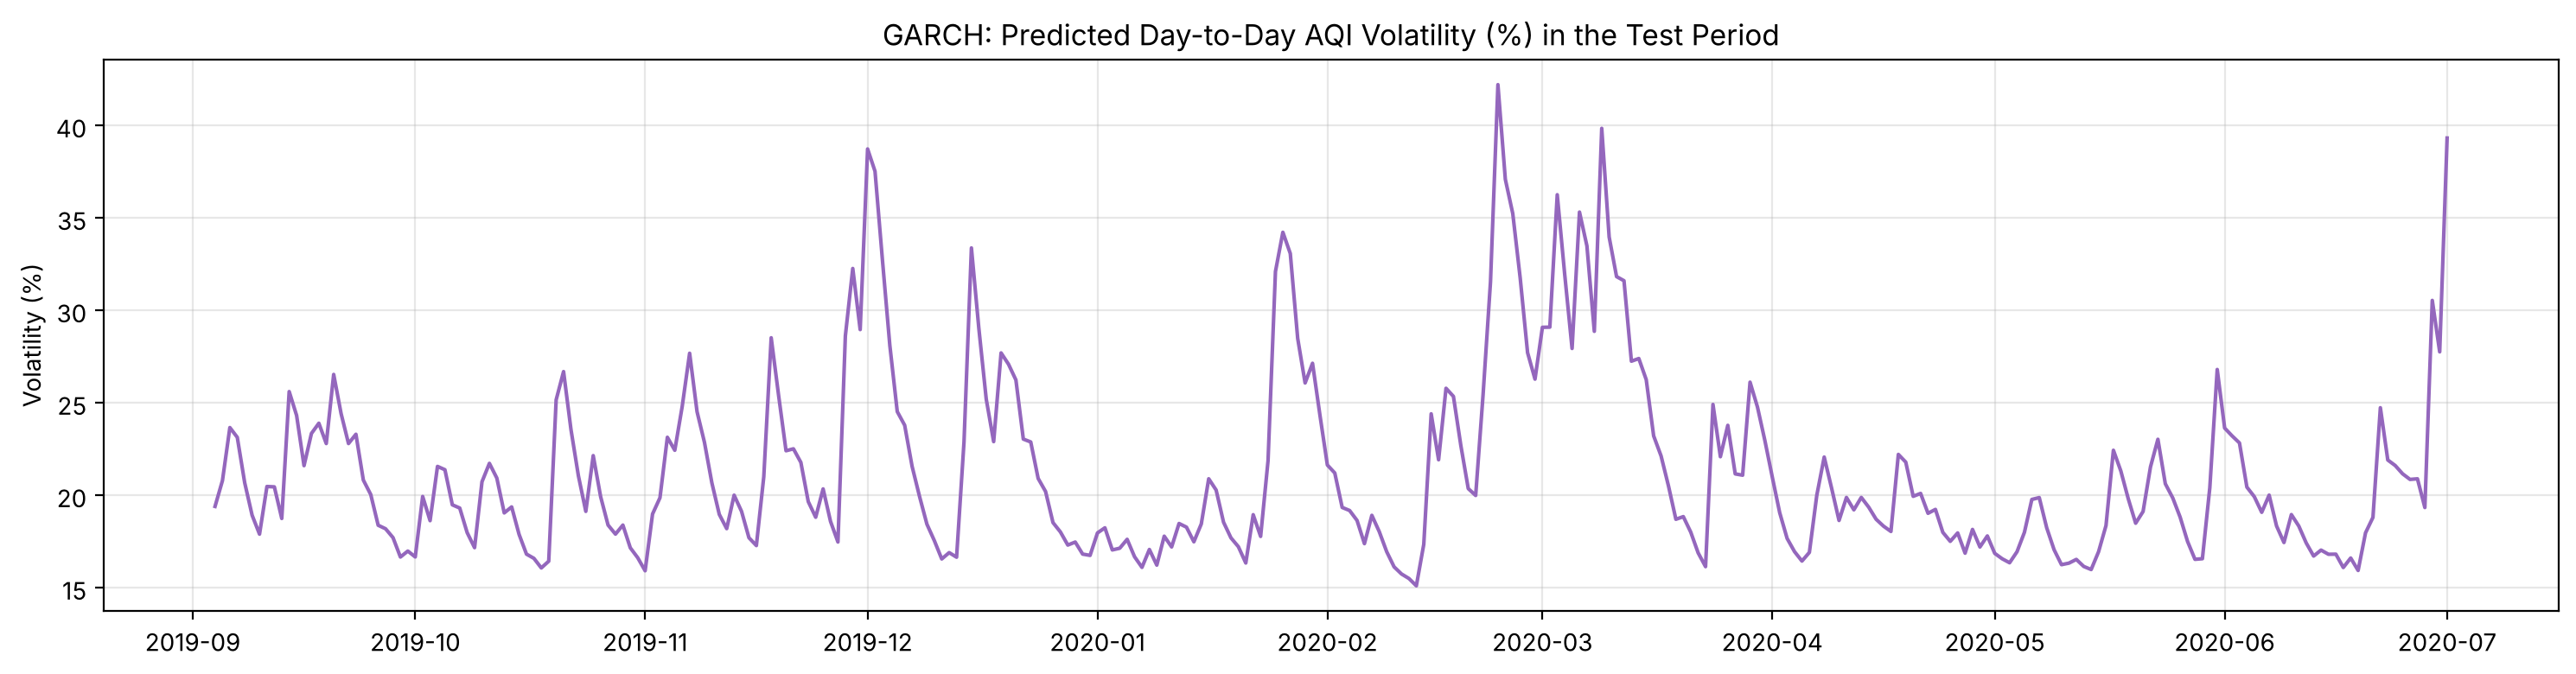

VAR lag order chosen by AIC: 14
VAR(14)                             RMSE=36.35  MAE=26.40  MAPE=13.46%


In [ ]:
from arch import arch_model
from statsmodels.tsa.api import VAR

# ---------- AR(1)-GARCH(1,1) on daily % change of AQI ----------
returns = 100 * log_y.diff().dropna()
history_r = returns.loc[:val_y.index[-1]]
garch_fit = arch_model(history_r, mean="AR", lags=1, vol="GARCH", p=1, q=1).fit(disp="off")
print(garch_fit.summary().tables[1])

# same parameters on the full series -> next-day forecast made each day
garch_full = arch_model(returns, mean="AR", lags=1, vol="GARCH", p=1, q=1).fix(garch_fit.params)
fc = garch_full.forecast(start=val_y.index[-1], horizon=1, reindex=False)
next_change = fc.mean["h.1"].shift(1).loc[test_y.index]          # forecast made the day before
next_vol = np.sqrt(fc.variance["h.1"]).shift(1).loc[test_y.index]
evaluate("AR-GARCH(1,1)", np.exp(log_y.shift(1).loc[test_y.index] + next_change / 100), "Statistical")

plt.figure(figsize=(15, 4))
plt.plot(next_vol, color="tab:purple")
plt.title("GARCH: Predicted Day-to-Day AQI Volatility (%) in the Test Period")
plt.ylabel("Volatility (%)"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------- VAR ----------
var_cols = ["AQI", "PM2.5", "PM10", "NO2"]
var_data = log_df[var_cols]
var_fit = VAR(var_data.iloc[:val_end]).fit(maxlags=14, ic="aic")
k = var_fit.k_ar
print("VAR lag order chosen by AIC:", k)
var_pred = [var_fit.forecast(var_data.values[i - k:i], steps=1)[0, 0] for i in range(val_end, n)]
evaluate(f"VAR({k})", np.exp(var_pred), "Statistical")

## 8. Comparative analysis of all models

,RMSE,MAE,MAPE (%),Group,Below 20% target
GRU (tuned),36.67,26.27,13.32,Deep Learning,Yes
VAR(14),36.35,26.40,13.46,Statistical,Yes
LSTM (tuned),37.32,27.04,13.54,Deep Learning,Yes
XGBoost (tuned),37.05,26.37,13.74,Machine Learning,Yes
Transformer (PatchTST-style),39.28,28.77,15.51,Deep Learning,Yes
"ARIMA(2,1,2)",47.34,34.52,17.04,Classical,Yes
"ARMA(2,1)",46.86,33.99,17.20,Classical,Yes
Naive (tomorrow = today),48.25,34.50,17.25,Baseline,Yes
Prophet (tuned),44.30,32.29,17.34,Statistical,Yes
"AR-GARCH(1,1)",48.47,34.84,17.42,Statistical,Yes


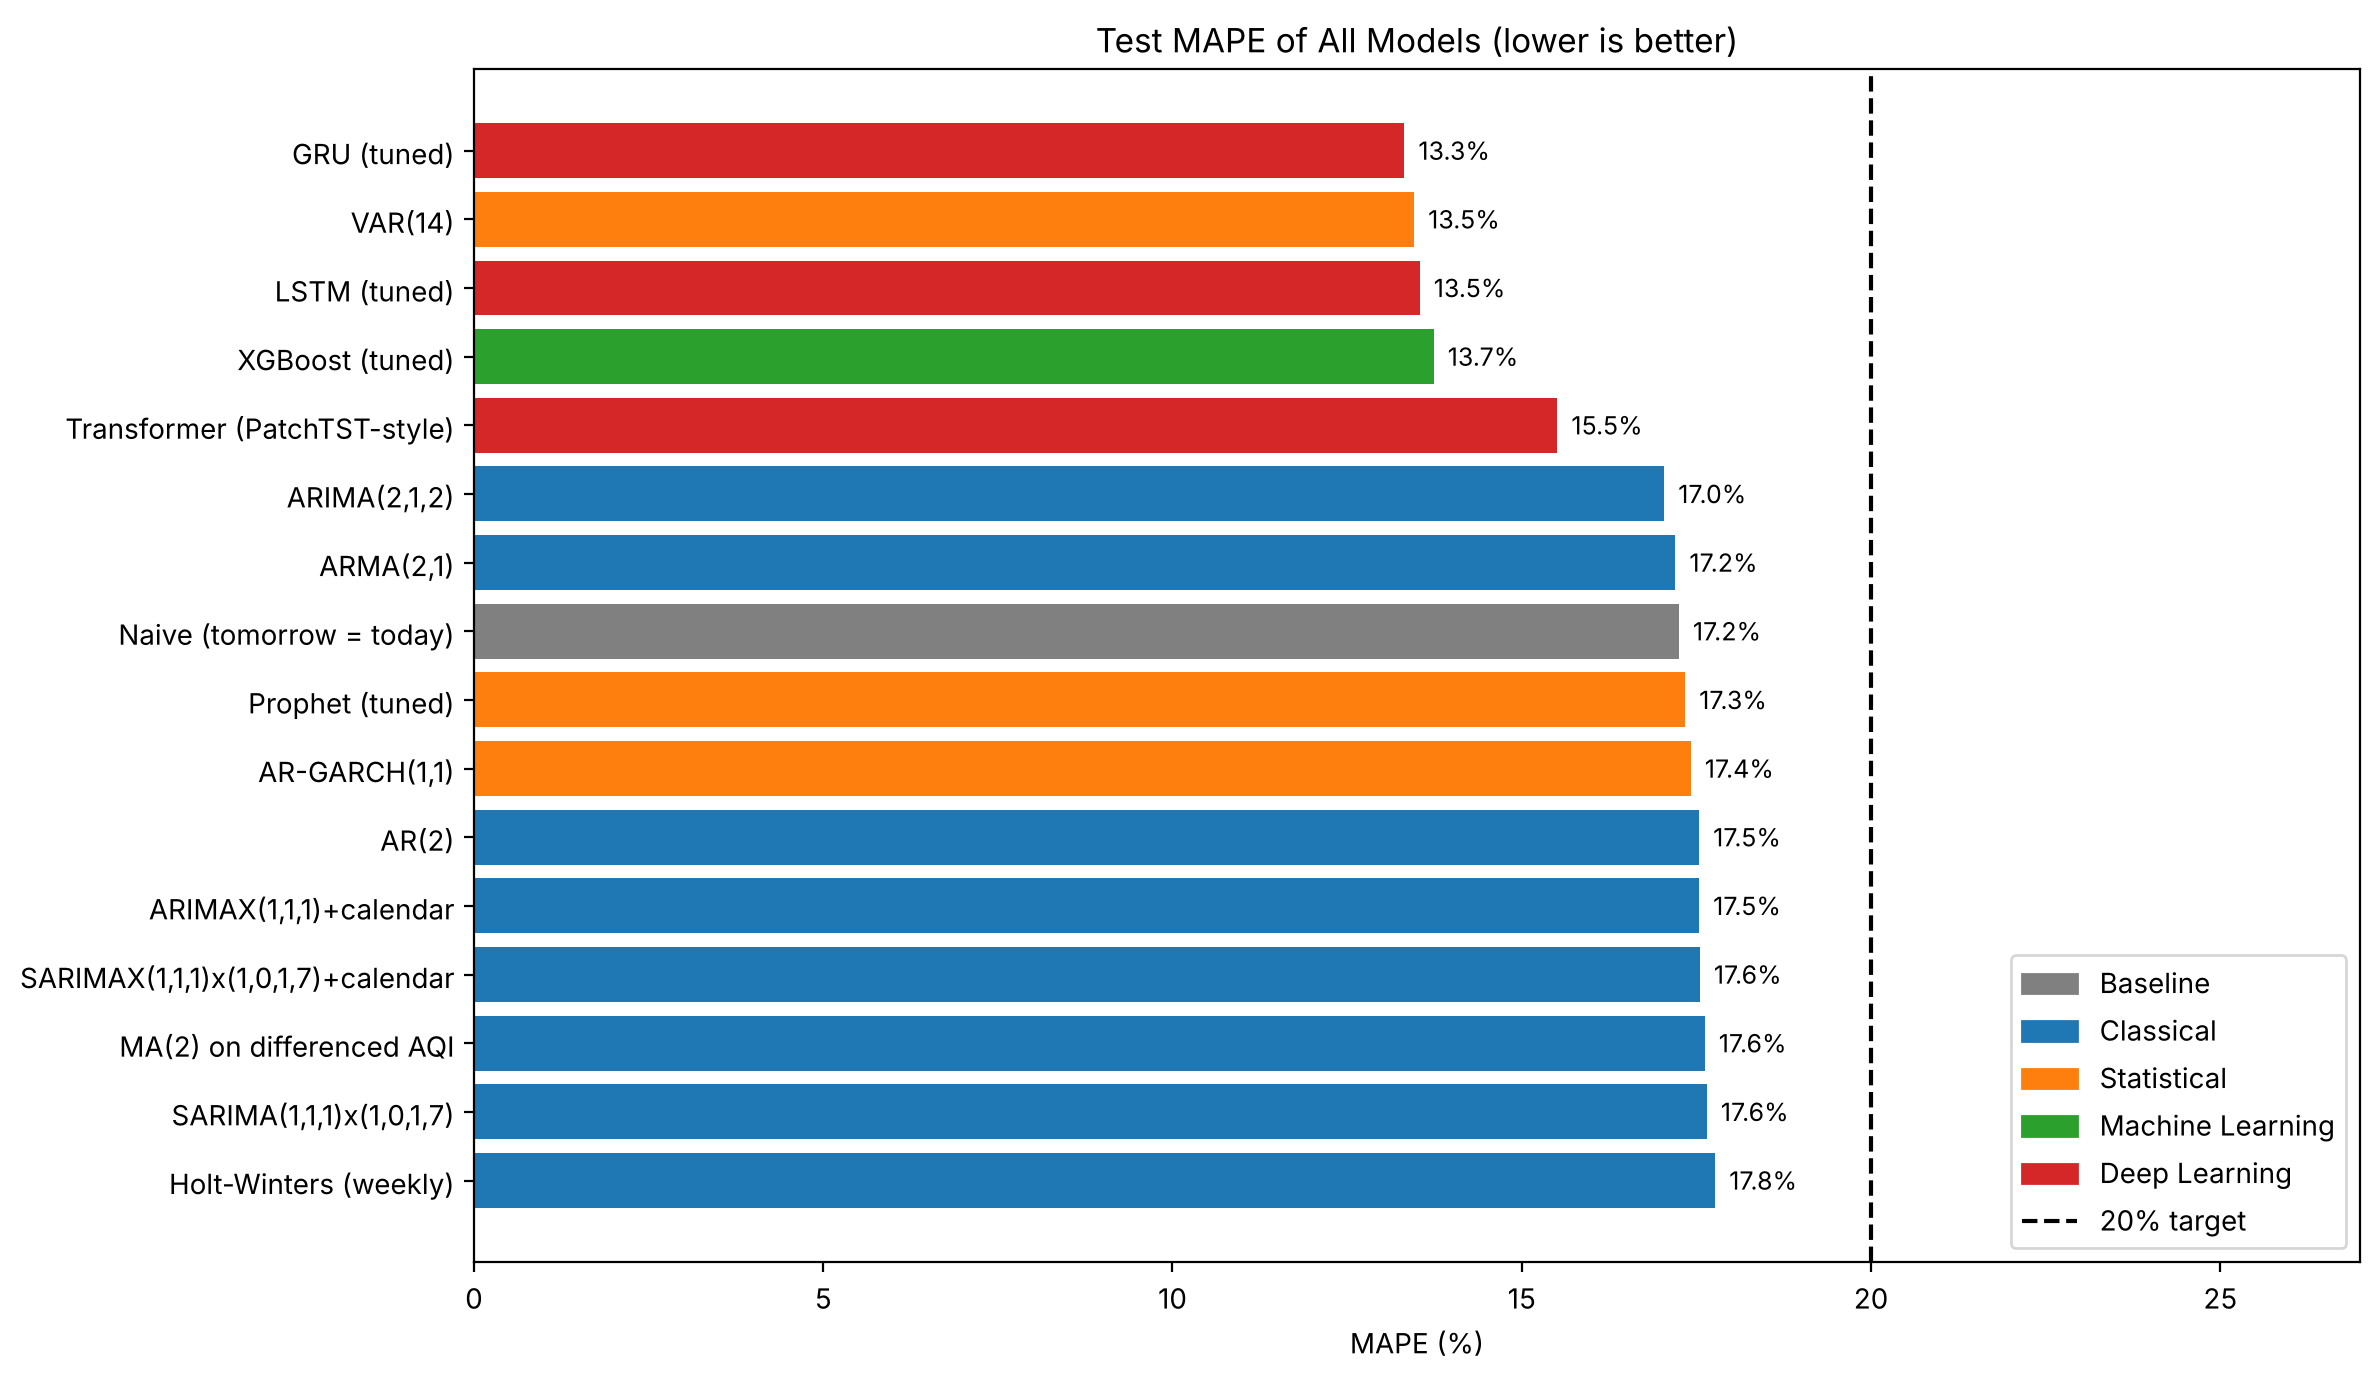

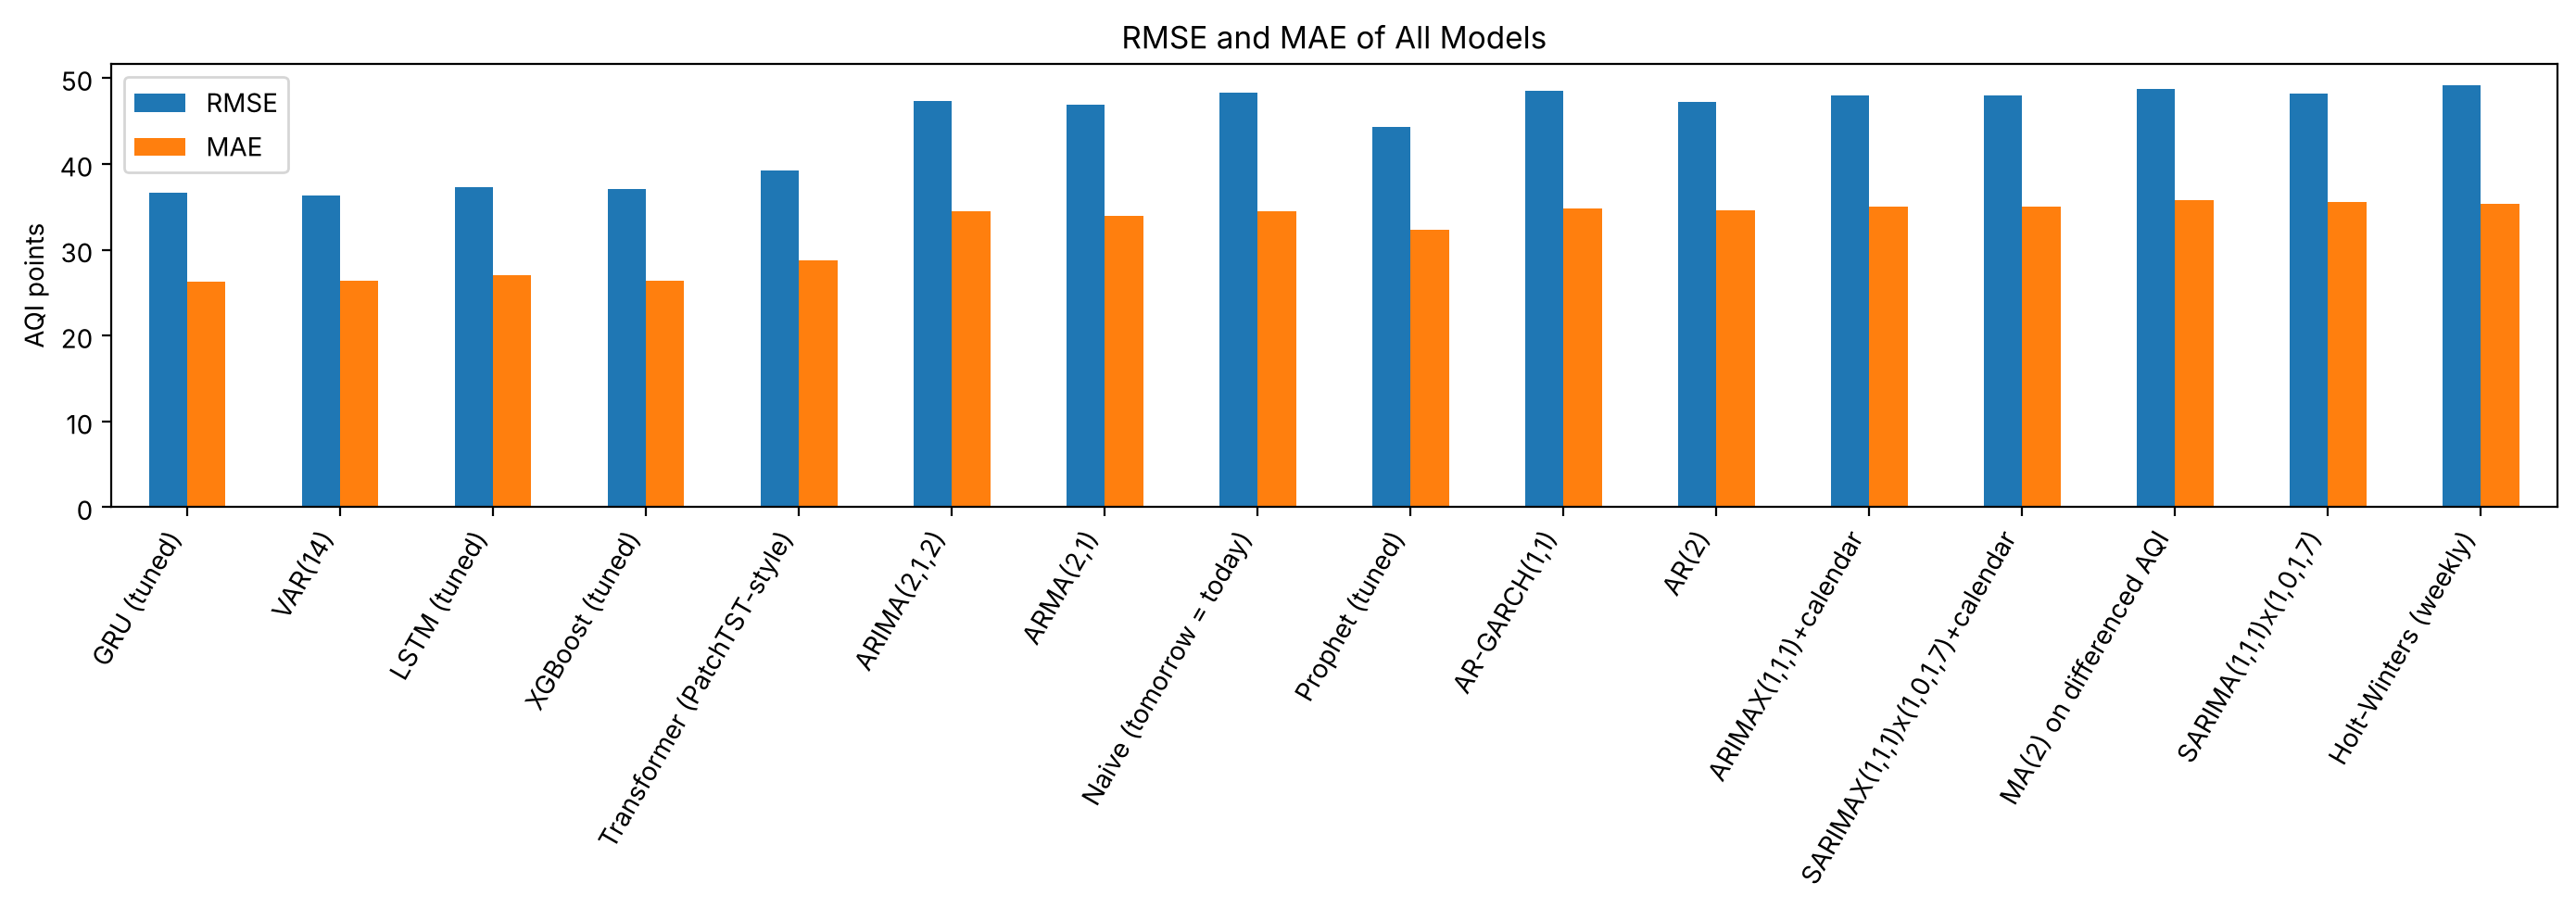

In [ ]:
final_table = pd.DataFrame(results).T
final_table[["RMSE", "MAE", "MAPE (%)"]] = final_table[["RMSE", "MAE", "MAPE (%)"]].astype(float).round(2)
final_table = final_table.sort_values("MAPE (%)")
final_table["Below 20% target"] = np.where(final_table["MAPE (%)"] < 20, "Yes", "No")
display(final_table)

# Bar chart of MAPE
colors = {"Baseline": "grey", "Classical": "tab:blue", "Statistical": "tab:orange",
          "Machine Learning": "tab:green", "Deep Learning": "tab:red"}
plt.figure(figsize=(12, 7))
plt.barh(final_table.index[::-1], final_table["MAPE (%)"][::-1],
         color=[colors[g] for g in final_table["Group"][::-1]])
plt.axvline(20, color="black", linestyle="--", label="20% target")
for i, v in enumerate(final_table["MAPE (%)"][::-1]):
    plt.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
plt.legend(handles + [plt.Line2D([0], [0], color="black", linestyle="--")],
           list(colors.keys()) + ["20% target"], loc="lower right")
plt.xlim(0, 27)   # leave space on the right for the legend
plt.title("Test MAPE of All Models (lower is better)")
plt.xlabel("MAPE (%)"); plt.tight_layout(); plt.show()

# RMSE and MAE side by side
final_table[["RMSE", "MAE"]].plot(kind="bar", figsize=(14, 5), title="RMSE and MAE of All Models")
plt.ylabel("AQI points"); plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

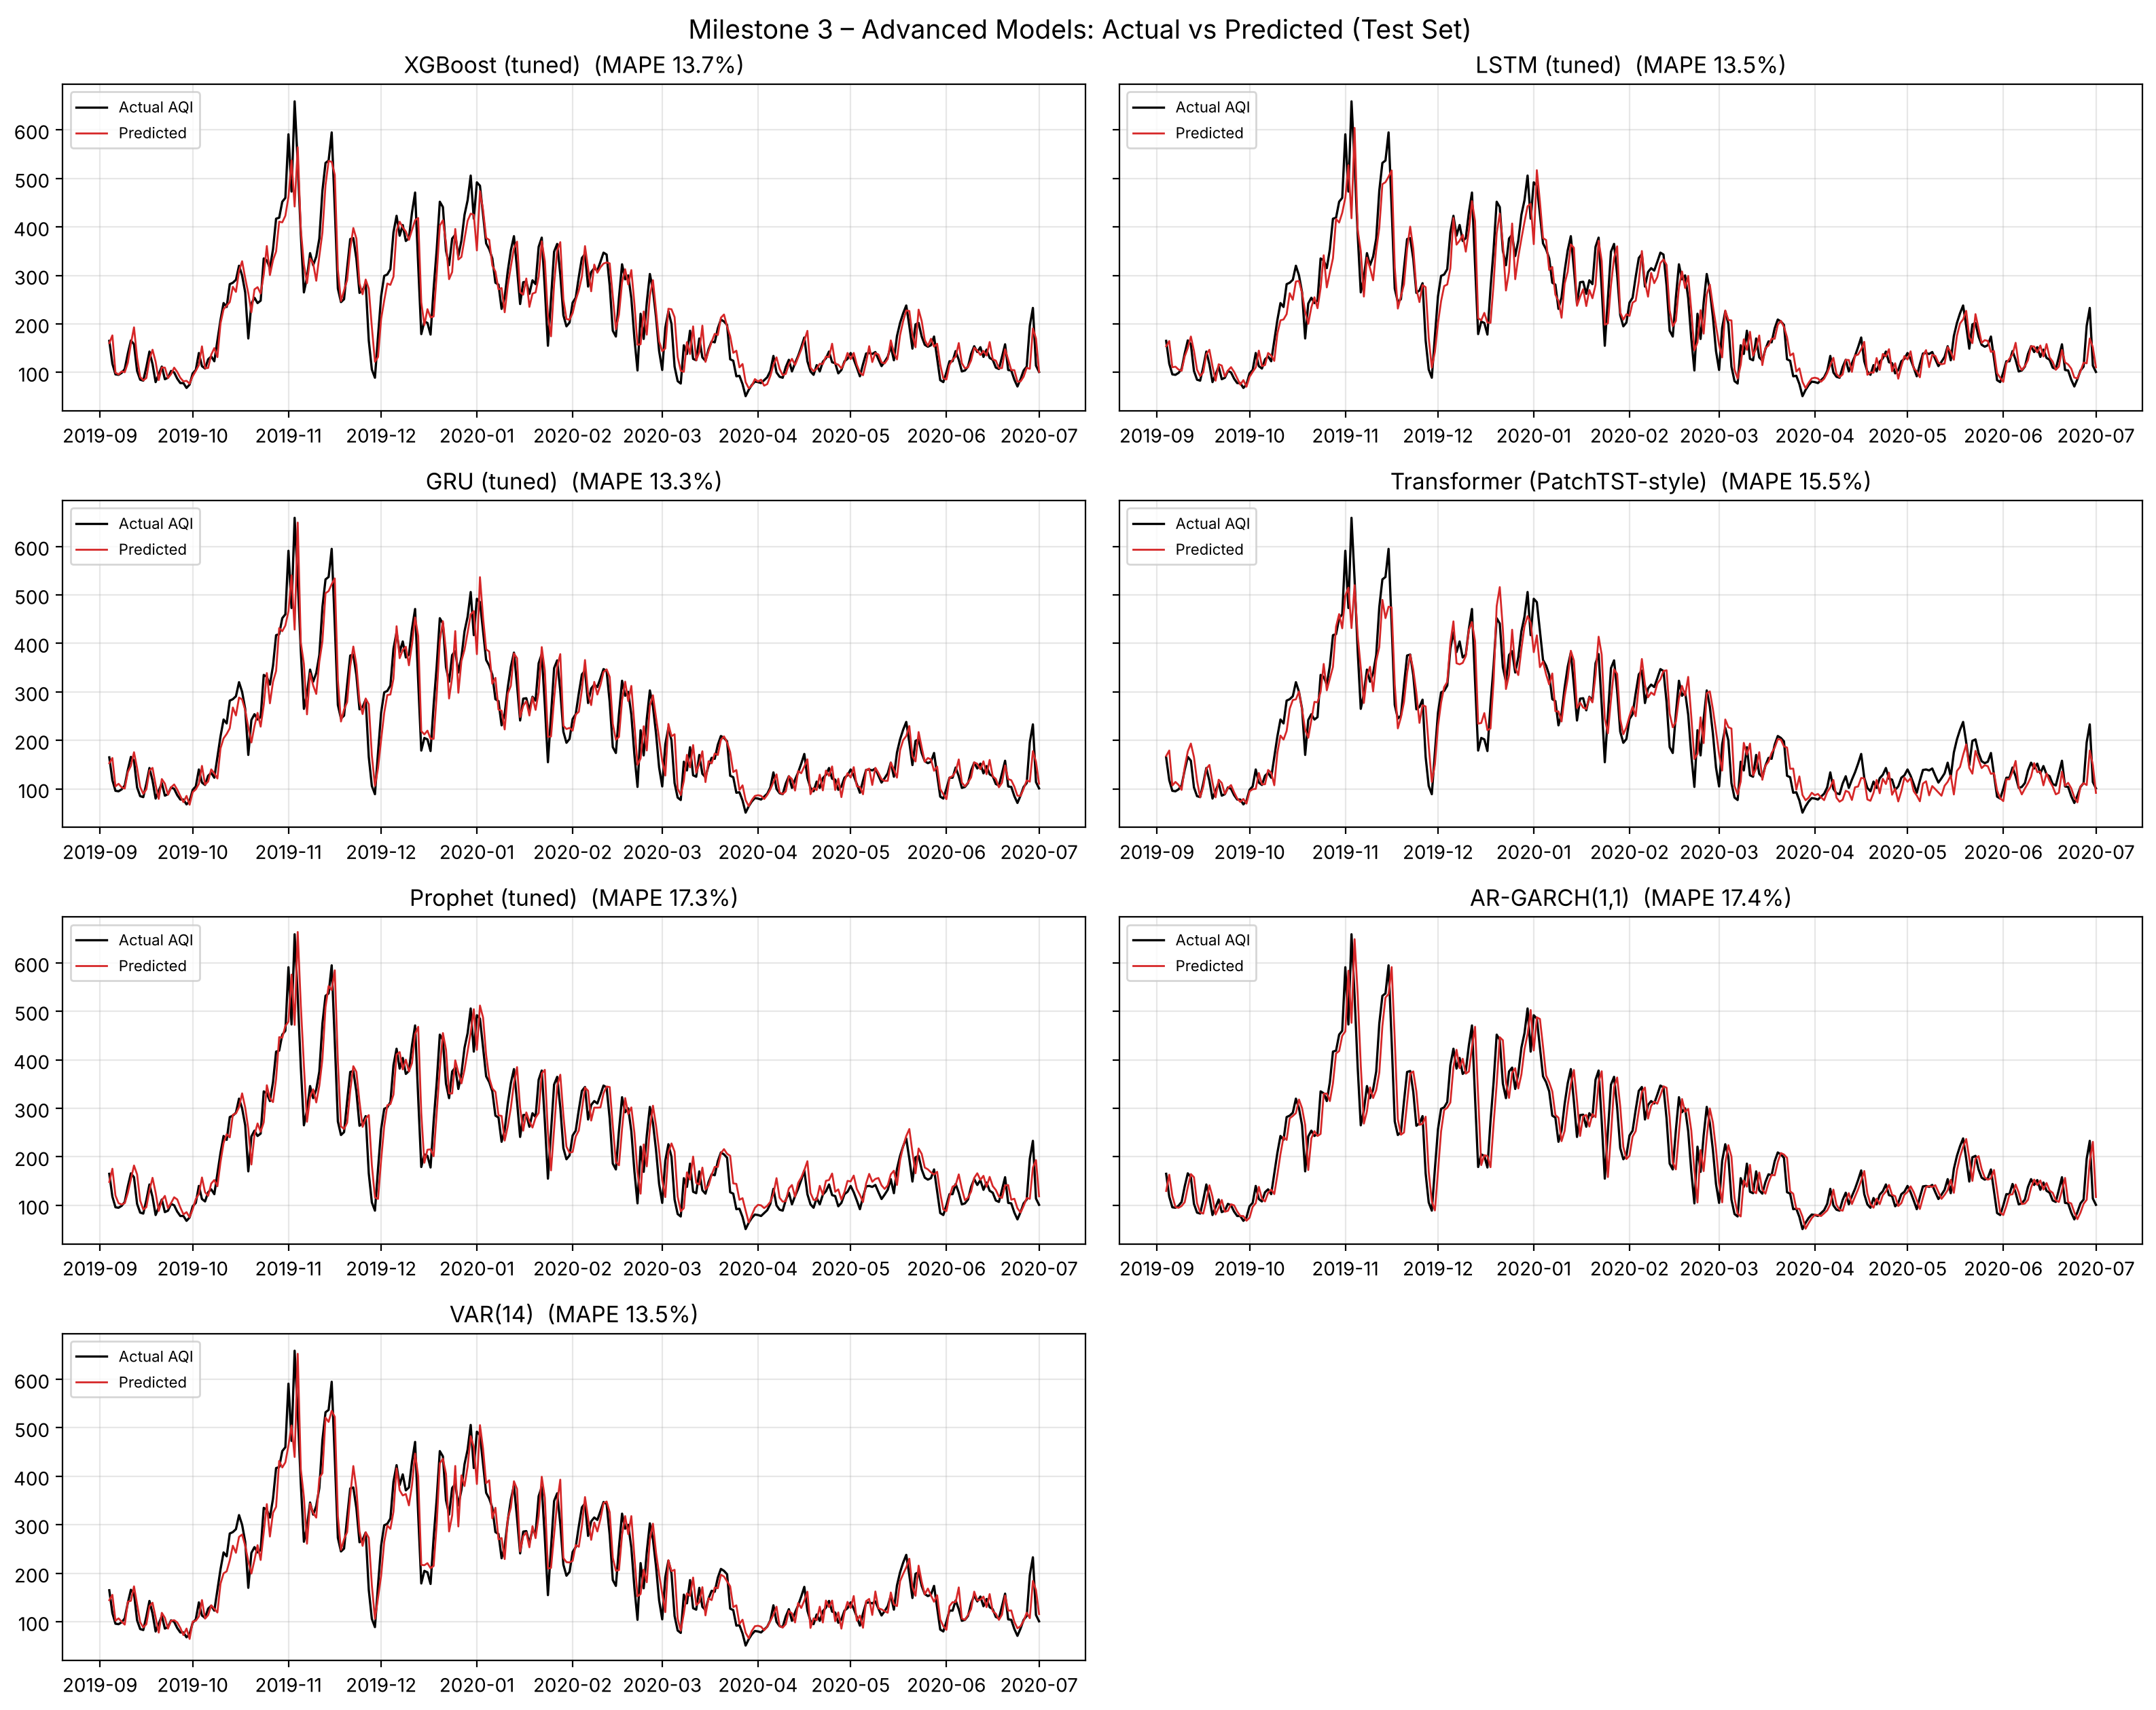

In [ ]:
m3_models = [m for m in predictions if results[m]["Group"] not in ("Classical", "Baseline")]
plot_forecasts(m3_models, "Milestone 3 – Advanced Models: Actual vs Predicted (Test Set)")

## 9. Best model: forecast, residuals and AQI category accuracy

Best model: GRU (tuned)
RMSE        36.67
MAE         26.27
MAPE (%)    13.32
Name: GRU (tuned), dtype: float64


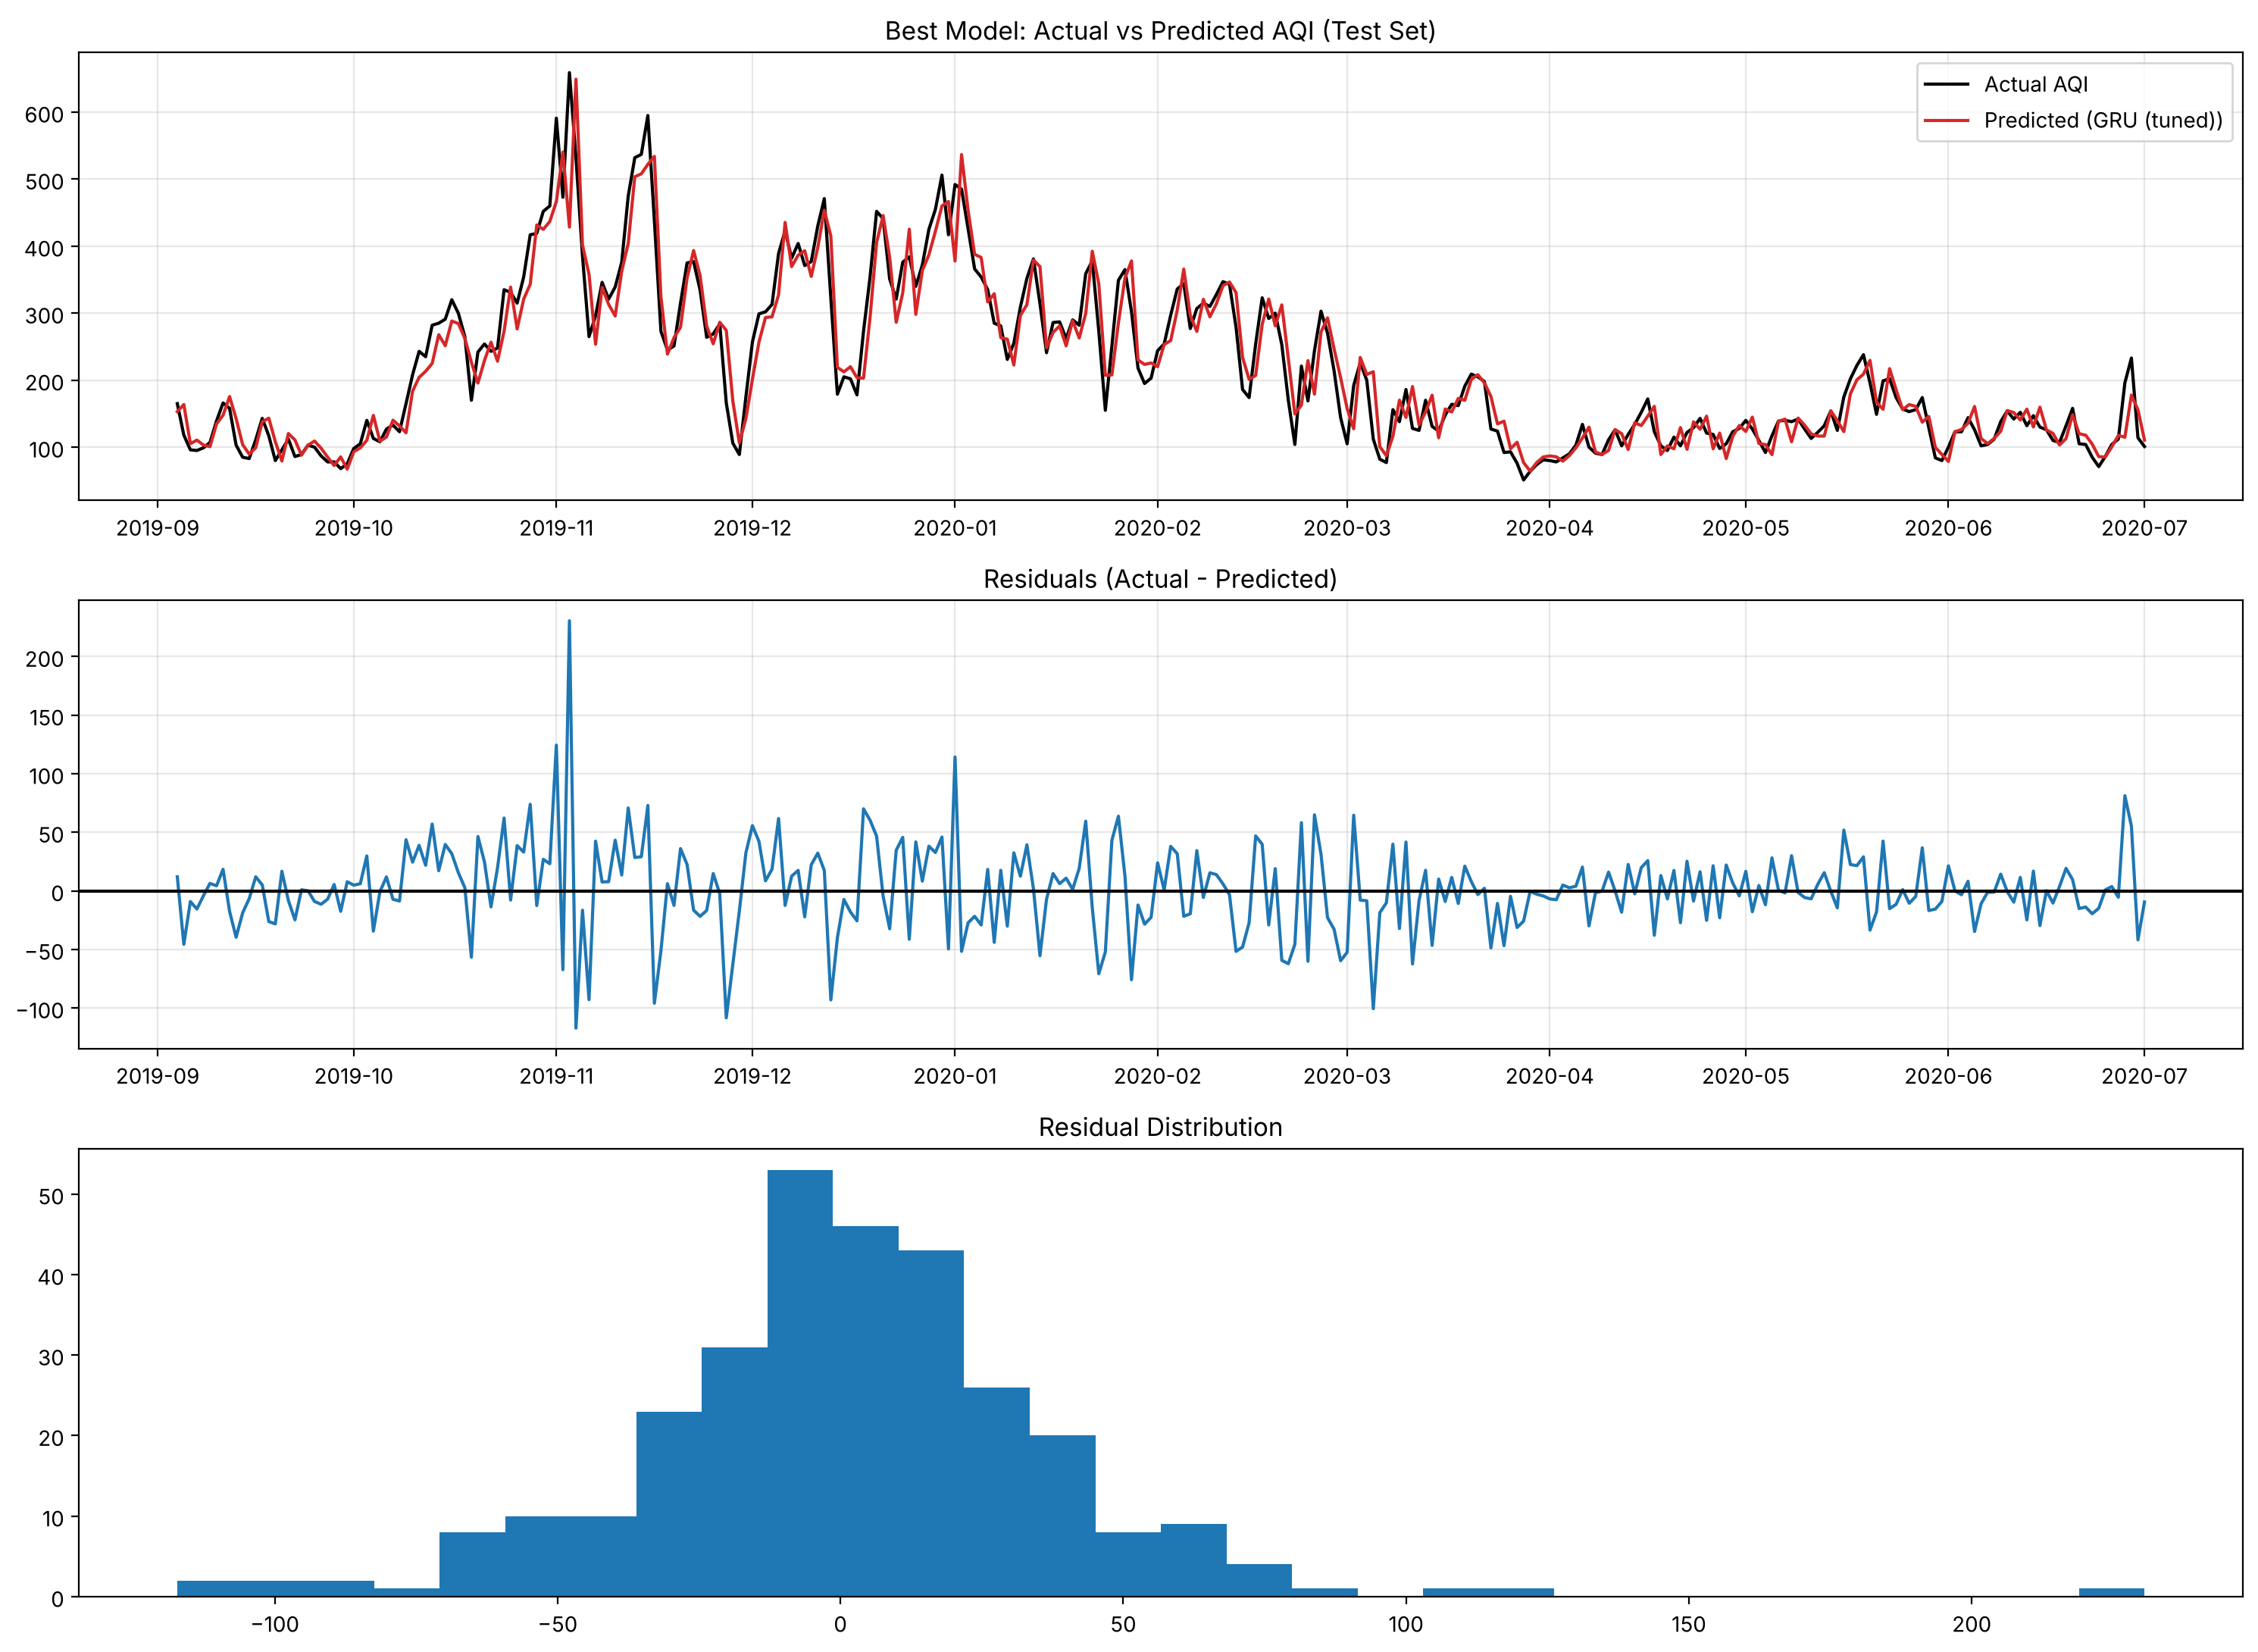


Correct AQI category predicted on 73.8% of test days


Predicted,Satisfactory,Moderate,Poor,Very Poor,Severe
Actual,,,,,
Satisfactory,26,16,0,0,0
Moderate,11,99,14,0,0
Poor,0,6,47,7,0
Very Poor,0,0,17,30,3
Severe,0,0,0,5,21


Unhealthy days (AQI > 200) correctly warned: 130 of 136
False alarms: 14


In [ ]:
best_name = final_table.index[0]
best_pred = predictions[best_name]
print("Best model:", best_name)
print(final_table.loc[best_name, ["RMSE", "MAE", "MAPE (%)"]])

fig, axes = plt.subplots(3, 1, figsize=(15, 11))
axes[0].plot(test_y, color="black", label="Actual AQI")
axes[0].plot(best_pred, color="tab:red", label=f"Predicted ({best_name})")
axes[0].set_title("Best Model: Actual vs Predicted AQI (Test Set)"); axes[0].legend(); axes[0].grid(alpha=0.3)

residuals = test_y - best_pred
axes[1].plot(residuals, color="tab:blue"); axes[1].axhline(0, color="black")
axes[1].set_title("Residuals (Actual - Predicted)"); axes[1].grid(alpha=0.3)
axes[2].hist(residuals, bins=30, color="tab:blue")
axes[2].set_title("Residual Distribution")
plt.tight_layout(); plt.show()

# Official CPCB AQI categories
bins = [0, 50, 100, 200, 300, 400, 1000]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
actual_cat = pd.cut(test_y, bins=bins, labels=labels)
pred_cat = pd.cut(best_pred, bins=bins, labels=labels)
print(f"\nCorrect AQI category predicted on {np.mean(actual_cat == pred_cat) * 100:.1f}% of test days")
display(pd.crosstab(actual_cat, pred_cat, rownames=["Actual"], colnames=["Predicted"]))

# Can the model warn about unhealthy days (AQI > 200, Poor or worse)?
actual_bad, pred_bad = test_y > 200, best_pred > 200
print(f"Unhealthy days (AQI > 200) correctly warned: {(actual_bad & pred_bad).sum()} of {actual_bad.sum()}")
print(f"False alarms: {(~actual_bad & pred_bad).sum()}")

In [ ]:
# Error by season: where is forecasting hardest?
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
              6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Post-monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
season = test_y.index.month.map(season_map)
season_error = pd.DataFrame({"Actual": test_y, "Error %": np.abs(residuals) / test_y * 100,
                             "Season": season}).groupby("Season").agg(
    avg_AQI=("Actual", "mean"), MAPE=("Error %", "mean"), days=("Actual", "count")).round(1)
display(season_error)

,avg_AQI,MAPE,days
Season,,,
Monsoon,124.9,12.1,31
Post-monsoon,242.1,13.5,88
Summer,132.7,14.7,92
Winter,309.2,12.1,91
